<a href="https://colab.research.google.com/github/LujainAldujain/Data_Mining_Project/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#[1] Problem

Customer churn, the movement of a customer from one service provider to another, is a major challenge for telecommunications companies. Losing customers directly reduces revenue and long-term growth, and because many providers are available, customers can switch easily when their needs or expectations are not met. Retaining an existing customer is also considerably cheaper than acquiring a new one. For example, in the study of the Syrian operator SyriaTel by Ahmad et al. [1], the company estimated that acquiring a new customer costs six times more than retaining a customer who is likely to churn.

The problem addressed in this project is therefore twofold:

1. **Can we predict whether a customer will churn**, based on the customer's demographics, subscribed services, and account information?
2. **Which groups of customers exist** in terms of their characteristics and service usage, and how does churn differ between these groups?

Answering these questions helps a telecom company identify customers at risk of leaving early enough to take retention actions, and understand which customer profiles are associated with churn. This supports better business decisions, improved customer satisfaction, and more targeted retention strategies.

#[2] Data Mining Task

The problem is formalized as two data mining tasks:

**1. Classification (supervised learning)**
* **Goal:** predict the binary class label `Churn` (Yes = 1, No = 0) for each customer.
* **Input:** the 19 descriptive attributes of the preprocessed dataset (all attributes except the identifier `customerID` and the class label).
* **Technique:** Decision Tree classification with two attribute selection measures, the **Gini Index** and **Information Gain (Entropy)** [3].
* **Evaluation:** three training/testing partitions (90/10, 80/20, and 70/30), compared using accuracy and confusion matrices.

**2. Clustering (unsupervised learning)**
* **Goal:** group customers with similar characteristics into segments, without using the class label.
* **Input:** the same 19 attributes, standardized before clustering. `Churn` is excluded from the clustering and used only afterwards to interpret the churn rate of each cluster.
* **Technique:** K-Means clustering with K = 2, 3, and 4 [3].
* **Evaluation:** the average Silhouette coefficient [4], the total within-cluster sum of squares (Elbow method), and visualization of the resulting clusters.

All experiments are implemented in Python on Google Colab using pandas [7], scikit-learn [5], matplotlib [8], and Yellowbrick [6].

#[3] Data

This section describes the selected dataset (Phase 1) and presents the data analysis performed before preprocessing (Phase 2).


### 3.1 Dataset Source

The Telco Customer Churn dataset was obtained from Kaggle [2]: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

### 3.2 Dataset Description

**Features:**

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/treselle-systems/customer_churn_analysis/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


**Number of Objects :**

In [ ]:
print(f"- Rows (instances): {df.shape[0]}")

- Rows (instances): 7043


**Class Distribution :**

In [ ]:
count_0 = df[df["Churn"] == "No"].shape[0]
count_1 = df[df["Churn"] == "Yes"].shape[0]

print("Target Column (class attribute): Churn")
print(f"- Customers with NO churn (No): {count_0}")
print(f"- Customers WITH churn (Yes): {count_1}")

Target Column (class attribute): Churn
- Customers with NO churn (No): 5174
- Customers WITH churn (Yes): 1869


#### Attributes & Data Types Breakdown

1. **Numerical Attributes (3 Features):**
   * `SeniorCitizen` (`int64`): A binary indicator (1 for senior citizens, 0 otherwise).
   * `tenure` (`int64`): Discrete numeric feature indicating the total number of months the customer has stayed with the service provider.
   * `MonthlyCharges` (`float64`): Continuous numeric feature showing the amount billed to the customer each month.

2. **Categorical / Text Attributes (18 Features):**
   * Stored under the `object` data type in Pandas.
   * **Demographic Details:** `gender`, `Partner`, `Dependents`.
   * **Subscribed Services:** `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`.
   * **Account & Billing Details:** `customerID` (unique identifier), `Contract`, `PaperlessBilling`, `PaymentMethod`.
   * **Target Class Label:** `Churn` (identifies whether the customer left the company: *Yes* or *No*).

---

#### Key Observations
* **Attribute Type Inconsistency:** The attribute `TotalCharges` is currently stored as an `object` (string/categorical) data type rather than a floating-point numeric type (`float64`). This occurs because newly subscribed customers (with `tenure = 0`) have blank whitespace strings (`" "`) instead of numerical zero values. This issue will be resolved during the data preprocessing phase by converting the column into a numeric type and handling the resulting missing values.

**Dataset Sample: sample of the raw dataset.**

In [ ]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 3.3 Data Analysis


#### Statistical Summary

The statistical summary provides the count, mean, standard deviation, minimum, quartiles, and maximum values for the numerical attributes. It helps in understanding the distribution and spread of the data.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/treselle-systems/customer_churn_analysis/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']

In [ ]:
df[numeric_columns].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


##### Interpretation of the Statistical Summary

* **Count:** `tenure` and `MonthlyCharges` contain values for all 7,043 customers, while `TotalCharges` contains only 7,032 values. The 11 missing values are investigated in the Missing Values Analysis below.
* **Mean and standard deviation:** The average customer has stayed with the company for 32.37 months and pays $64.76 per month, with an accumulated total of $2,283.30. The standard deviation of `tenure` (24.56 months) is about 76% of its mean, and the standard deviation of `TotalCharges` ($2,266.77) is almost equal to its mean (about 99%). Both attributes are therefore highly dispersed: the dataset contains brand-new customers as well as customers who have stayed for several years. `MonthlyCharges` is less dispersed, with a standard deviation ($30.09) of about 46% of its mean.
* **Mean compared with median (50%):** For `tenure` the mean (32.37) is slightly higher than the median (29), and for `TotalCharges` the mean ($2,283.30) is about 63% higher than the median ($1,397.48). Both are therefore right-skewed, with a small number of long-standing, high-paying customers pulling the mean upwards. For `MonthlyCharges` the opposite holds: the mean ($64.76) is lower than the median ($70.35), so this attribute is left-skewed. The five-number summary below examines these distributions in more detail.

#### Five-Number Summary

The five-number summary includes the minimum, first quartile (Q1), median (Q2), third quartile (Q3), and maximum values. These values help describe the distribution and range of each numerical attribute.

In [ ]:
df[numeric_columns].describe().loc[['min', '25%', '50%', '75%', 'max']]

##### Interpretation of the Five-Number Summary

The five numbers divide each attribute into four groups that each contain about 25% of the customers:

* **Minimum:** the smallest observed value.
* **First quartile (Q1):** 25% of the customers have a value at or below Q1.
* **Median (Q2):** the middle value; half of the customers are below it and half are above it.
* **Third quartile (Q3):** 75% of the customers have a value at or below Q3.
* **Maximum:** the largest observed value.

From these values we also derive the **range** (Maximum − Minimum), the **interquartile range** (IQR = Q3 − Q1, the spread of the middle 50% of customers), and the IQR outlier fences (Q1 − 1.5·IQR and Q3 + 1.5·IQR).

| Attribute | Minimum | Q1 | Median | Q3 | Maximum | Range | IQR |
|---|---|---|---|---|---|---|---|
| `tenure` (months) | 0 | 9 | 29 | 55 | 72 | 72 | 46 |
| `MonthlyCharges` ($) | 18.25 | 35.50 | 70.35 | 89.85 | 118.75 | 100.50 | 54.35 |
| `TotalCharges` ($) | 18.80 | 401.45 | 1,397.48 | 3,794.74 | 8,684.80 | 8,666.00 | 3,393.29 |

**tenure:** Tenure ranges from 0 months (customers who have just joined and have not completed their first billing month) to 72 months (6 years). A quarter of the customers have been with the company for 9 months or less, and half of them for 29 months (about 2.4 years) or less. The upper half of the distribution is more spread out than the lower half: the distance from the median to Q3 (26 months) is larger than the distance from Q1 to the median (20 months), and the distance from Q3 to the maximum (17 months) is larger than the distance from the minimum to Q1 (9 months). Together with the mean (32.37) being above the median, this indicates a mild right skew. The IQR of 46 months shows that even the middle half of the customers differ widely in how long they have stayed. Since a large share of customers are relatively new, `tenure` is expected to be an important attribute for distinguishing customers who churn from loyal customers.

**MonthlyCharges:** Monthly charges range from $18.25 to $118.75. The lowest quarter of customers is packed into a narrow band of only $17.25 (from $18.25 to $35.50), which indicates a large group of customers on low-cost plans; this agrees with the tall bars at the low-fee end of the histogram below. The median ($70.35) is much closer to Q3 ($89.85) than to Q1 ($35.50): the gap from Q1 to the median is $34.85, while the gap from the median to Q3 is only $19.50. The lower half of the customers is therefore more spread out, and the distribution is left-skewed, which agrees with the mean ($64.76) being below the median. The wide IQR ($54.35) shows that customers subscribe to very different service bundles, ranging from basic to premium plans.

**TotalCharges:** Total charges range from $18.80 to $8,684.80 (based on the 7,032 non-missing values). The gaps between consecutive values grow steadily: $382.65 from the minimum to Q1, $996.03 from Q1 to the median, $2,397.26 from the median to Q3, and $4,890.06 from Q3 to the maximum. This is a strongly right-skewed distribution with a long upper tail: half of the customers have paid less than $1,397.48 in total, while the top quarter have paid between $3,794.74 and $8,684.80. This shape is expected, because `TotalCharges` accumulates the monthly charges over the customer's tenure. It therefore inherits the wide spread of `tenure`, and new customers can only have small totals.

**Outliers:** For all three attributes, the IQR fences lie outside the observed values, so none of the values is an outlier:

* `tenure`: the fences are −60 and 124, and the observed range is 0 to 72.
* `MonthlyCharges`: the fences are −46.03 and 171.38, and the observed range is 18.25 to 118.75.
* `TotalCharges`: the upper fence is 8,884.67, about $200 above the maximum of 8,684.80. The largest totals are close to the fence, but they belong to valid long-standing, high-paying customers rather than errors.

This agrees with the Outlier Analysis below, which finds 0 outliers.

**Differences between the attributes and their effect on preprocessing:** The three attributes are measured on very different scales. Their maximum values are 72, 118.75 and 8,684.80, and their IQRs are 46, 54.35 and 3,393.29. Without scaling, `TotalCharges` would dominate any distance-based data mining method, which motivates the Min-Max normalization applied in the preprocessing stage. The attributes also differ in shape: `tenure` is mildly right-skewed, `MonthlyCharges` is left-skewed, and `TotalCharges` is strongly right-skewed. Finally, since none of the attributes contains outliers, no observations need to be removed as noise.

<!-- EDIT: خلية جديدة: وصف وتفسير نتائج الـ five-number summary حسب ملاحظة الدكتورة على Phase 2 -->

#### Outlier Analysis

The IQR method was used to identify potential outliers in the numerical attributes. Values below Q1 - 1.5(IQR) or above Q3 + 1.5(IQR) were considered potential outliers. Detecting these values helps determine whether further preprocessing may be needed.

In [ ]:
for column in numeric_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("Attribute:", column)
    print("Number of Outliers:", len(outliers))
    print("--------------------------")

Attribute: tenure
Number of Outliers: 0
--------------------------
Attribute: MonthlyCharges
Number of Outliers: 0
--------------------------
Attribute: TotalCharges
Number of Outliers: 0
--------------------------


#### Boxplot of tenure
This plot shows the distribution of customer tenure (from 0 to 72 months) . It provides a visual representation of the median, quartiles, spread, and the absence of outliers.
However, the wide range of values clearly indicated the need to apply Normalization to standardize the scale of this feature with the rest of the dataset.


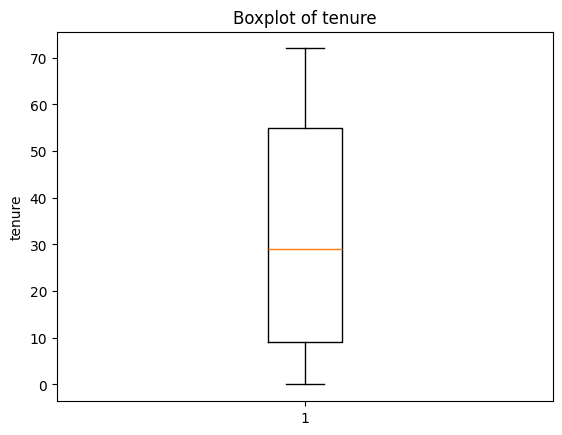

In [ ]:
plt.figure()
plt.boxplot(df['tenure'].dropna())
plt.title("Boxplot of tenure")
plt.ylabel("tenure")
plt.show()

#### Boxplot of MonthlyCharges
This plot displays the distribution of monthly charges with a median around 70 and no outliers , the high variance in the charges confirmed the decision to apply Min-Max Scaling as a necessary preprocessing step to prepare the data for the mining algorithms.

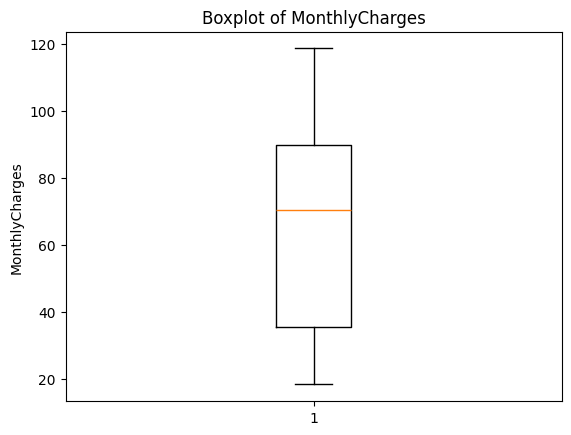

In [ ]:
plt.figure()
plt.boxplot(df['MonthlyCharges'].dropna())
plt.title("Boxplot of MonthlyCharges")
plt.ylabel("MonthlyCharges")
plt.show()

#### Boxplot of TotalCharges
This plot illustrates the total charges, showing a huge range (up to 8684) , though without mathematical outliers. This massive range finalized my decision to apply Normalization. Additionally, analyzing this feature highlighted the need to handle the previously discovered "missing values" as a crucial preprocessing step.

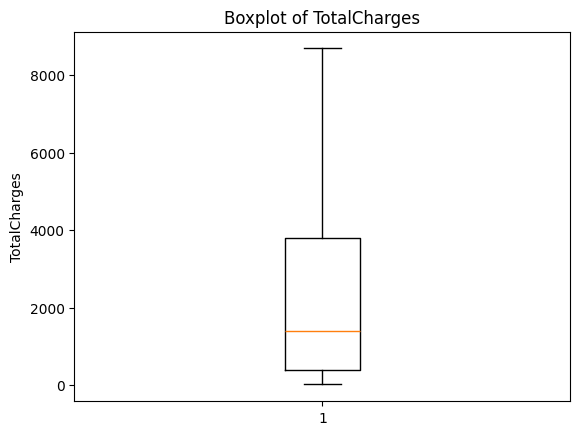

In [ ]:
plt.figure()
plt.boxplot(df['TotalCharges'].dropna())
plt.title("Boxplot of TotalCharges")
plt.ylabel("TotalCharges")
plt.show()

##### Numerical Data Analysis

The five-number summary, IQR method, and boxplots were used to analyze the numerical attributes.

These techniques provide information about the center, spread, and possible extreme values in the dataset. The results can help determine whether some numerical attributes require preprocessing before applying data mining techniques.

No outliers were removed in this section because this part focuses only on analyzing the data. Any necessary treatment will be performed during the preprocessing stage.

#### Missing Values Analysis


Missing Values:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


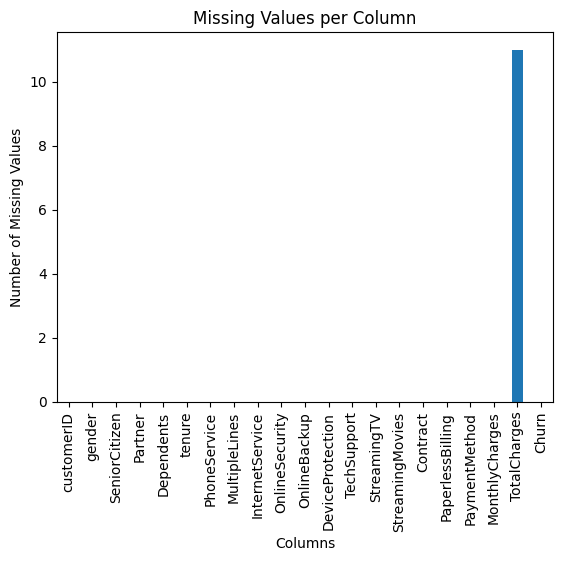

In [ ]:
missing = df.isnull().sum()
print("\nMissing Values:")
print(missing)

plt.figure()
missing.plot(kind='bar')
plt.title("Missing Values per Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.show()

The missing values analysis shows that the majority of columns in the dataset are complete, with no missing values detected. However, the `TotalCharges` column contains 11 missing (NaN) values, as shown in both the printed summary and the bar chart above. Since this affects less than 0.2% of the total records, it is unlikely to significantly impact the overall analysis, but the affected rows still require further investigation to understand why the data is missing before deciding how to handle them.

In [ ]:
missing_charges = df[df['TotalCharges'].isnull()]
print(f"Rows with missing TotalCharges: {len(missing_charges)}")
missing_charges[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Rows with missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


**All** 11 of these rows correspond to customers with `tenure = 0`, meaning they have not yet completed a single billing cycle. This strongly suggests these are newly signed-up customers who joined the service but had not been charged at the time the data was collected, rather than an error in data entry or a technical fault.

#### Plots & Variable Distributions

##### Bar Plot

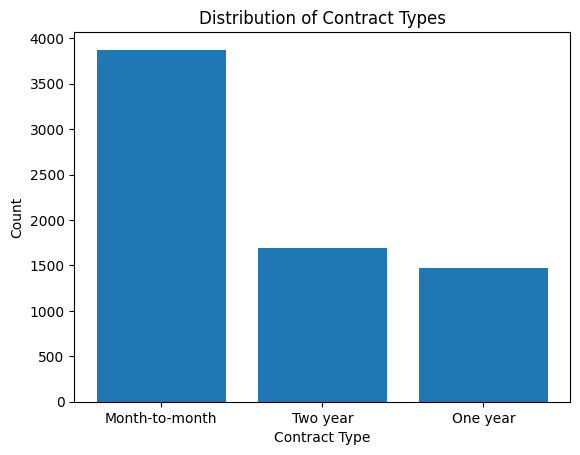

In [ ]:
contract_counts = df['Contract'].value_counts()
plt.figure()
plt.bar(contract_counts.index, contract_counts.values)
plt.title("Distribution of Contract Types")
plt.xlabel("Contract Type")
plt.ylabel("Count")
plt.show()

This bar plot shows the distribution of customer contract
types **(Contract)**. It reveals that month-to-month contracts are the most common compared to long-term contracts. This information helps us understand the nature of categorical data and guides us toward encoding them correctly before feeding them into mining algorithms.

##### Histogram

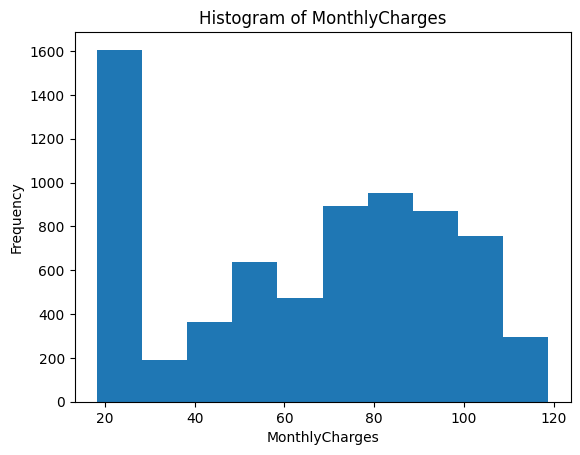

In [ ]:
plt.figure()
plt.hist(df['MonthlyCharges'])
plt.title("Histogram of MonthlyCharges")
plt.xlabel("MonthlyCharges")
plt.ylabel("Frequency")
plt.show()

The histogram illustrates the distribution of customers' monthly charges **(MonthlyCharges)**. It shows high concentrations of customers in the lower-fee tiers, indicating that the data distribution is irregular and suggesting a potential need for data transformation or normalization later in the data preprocessing stage.

##### Scatter Plot

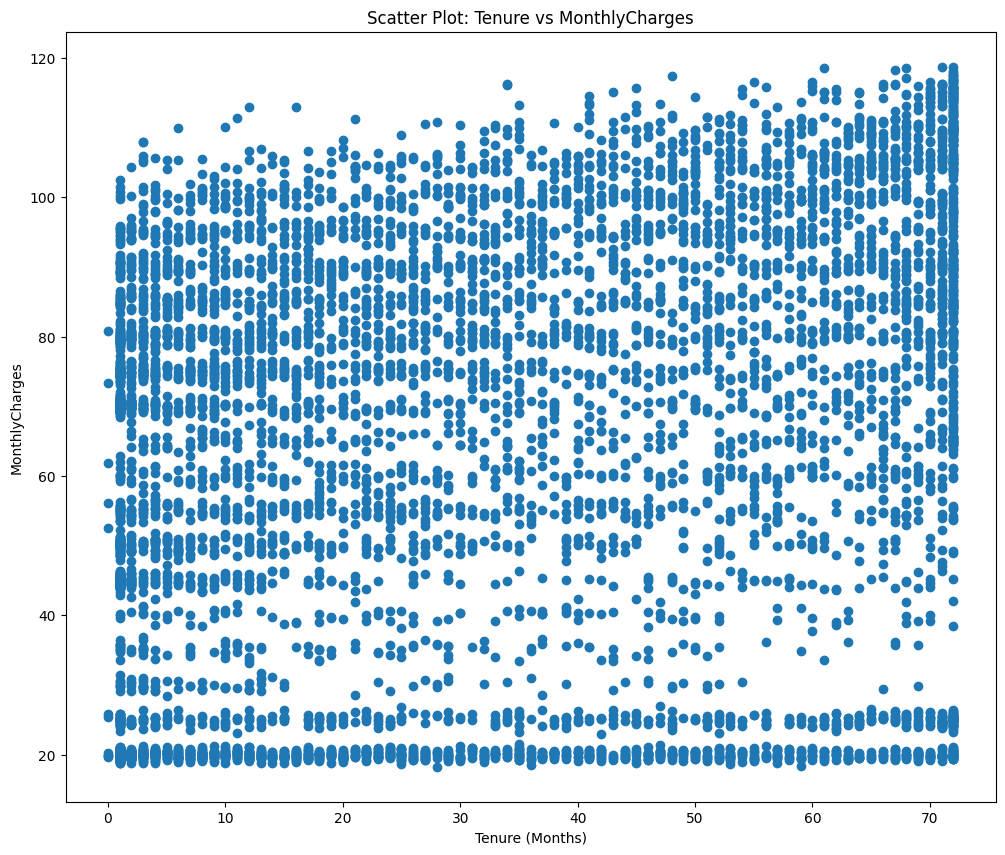

In [ ]:
plt.figure(figsize=(12, 10))
plt.scatter(df['tenure'], df['MonthlyCharges'])
plt.title("Scatter Plot: Tenure vs MonthlyCharges")
plt.xlabel("Tenure (Months)")
plt.ylabel("MonthlyCharges")
plt.show()

The scatter plot displays the relationship between customer tenure **(tenure)** and monthly charges **(MonthlyCharges)**. This plot assists us in visually identifying patterns or potential linear relationships between variables and spotting any clear outliers that require noise removal.

#### Class Label Distribution - Churn

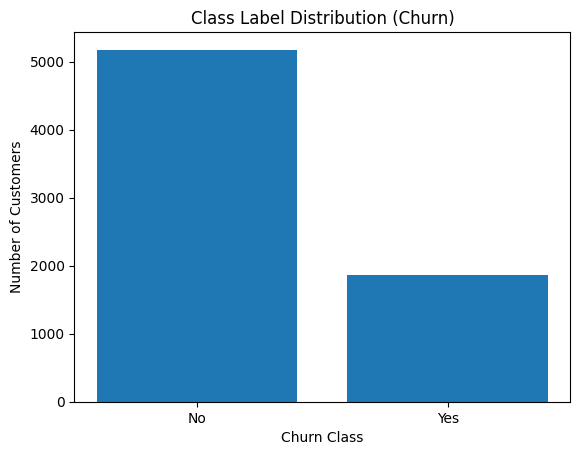

In [ ]:
churn_counts = df['Churn'].value_counts()
plt.figure()
plt.bar(churn_counts.index, churn_counts.values)
plt.title("Class Label Distribution (Churn)")
plt.xlabel("Churn Class")
plt.ylabel("Number of Customers")
plt.show()

This plot illustrates the distribution of the target class **(Churn)**, showing a disparity between the number of retained customers and churned customers. This highlights a slight class imbalance that must be addressed and evaluated during the classification model-building phase.

#[4] Data preprocessing

This section presents the preprocessing applied to the raw dataset in Phase 2. The preprocessed dataset was saved separately as `Dataset/Preprocessed_dataset.csv` and is the input to all data mining experiments in sections [5] and [6]. The raw dataset `Dataset/Raw_dataset.csv` was kept unchanged.

| Step | Technique | Attributes | Result |
|---|---|---|---|
| Missing values | Converted `TotalCharges` to numeric and filled missing values with 0 | `TotalCharges` | The 11 missing values (all customers with `tenure = 0`) were replaced; no missing values remain |
| Noise removal | IQR method (Q1 − 1.5·IQR, Q3 + 1.5·IQR) | `tenure`, `MonthlyCharges`, `TotalCharges` | No outliers were found; all 7,043 rows were kept |
| Normalization | Min-Max scaling to [0, 1] | `SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges` | Numerical attributes placed on a common scale |
| Variable transformation | Label encoding | 15 categorical attributes and `Churn` | All attributes except `customerID` became numerical |

### 4.1 Raw Dataset
  

In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/treselle-systems/customer_churn_analysis/master/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print(df.head())
print(df.info())
print(df.describe())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

### 4.2 Missing Values


In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

df = df.fillna(0)

print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


Missing values were checked to ensure the completeness of the dataset. The TotalCharges attribute was converted to numerical form, and any missing values were replaced with 0. After handling the missing values, there were no missing values remaining in the dataset. This ensured that the dataset was complete and ready for further preprocessing and analysis.

### 4.3 Data preprocessing techniques



#### 1- Noise Removal


In [ ]:
print("Rows before noise removal:", df.shape[0])

for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Rows after noise removal:", df.shape[0])

Noise removal was applied to detect and remove extreme values that could affect the analysis. The IQR method was applied to the numerical attributes, including tenure, MonthlyCharges, and TotalCharges, by calculating Q1, Q3, and the IQR and checking for values outside the lower and upper bounds. The number of rows remained 7043 after applying this technique, indicating that no outliers required removal. This confirmed that the numerical data was consistent and suitable for further analysis.

#### 2- Normalization


In [ ]:
from sklearn.preprocessing import MinMaxScaler

target_col = 'Churn'

num_cols_after = df.select_dtypes(include='number').columns.tolist()
scale_cols = [c for c in num_cols_after if c != target_col]

scaler = MinMaxScaler()
df[scale_cols] = scaler.fit_transform(df[scale_cols])

df.describe().T.head()

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.0,0.000000,0.000000,0.000000,1.0
tenure,7043.0,0.449599,0.341104,0.0,0.125000,0.402778,0.763889,1.0
MonthlyCharges,7043.0,0.462803,0.299403,0.0,0.171642,0.518408,0.712438,1.0
TotalCharges,7043.0,0.262497,0.261007,0.0,0.045891,0.160574,0.436003,1.0


Normalization was applied to reduce differences in the scales of the numerical attributes. Min-Max Normalization was used to transform the values of SeniorCitizen, tenure, MonthlyCharges, and TotalCharges into a range between 0 and 1. This placed the numerical attributes on a common scale and made the dataset more suitable for further data mining tasks.

#### 3- Variable Transformation


##### Encoding


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
categorical_columns = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
                       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
                       'PaperlessBilling', 'PaymentMethod', 'Churn']

for col in categorical_columns:
    df[col] = le.fit_transform(df[col])
    print(col, ":", dict(zip(le.classes_, range(len(le.classes_)))))

df.to_csv('Encoded_data.csv', index=False)
print("\nData after Label Encoding:")
print(df.head())

gender : {'Female': 0, 'Male': 1}
Partner : {'No': 0, 'Yes': 1}
Dependents : {'No': 0, 'Yes': 1}
PhoneService : {'No': 0, 'Yes': 1}
MultipleLines : {'No': 0, 'No phone service': 1, 'Yes': 2}
InternetService : {'DSL': 0, 'Fiber optic': 1, 'No': 2}
OnlineSecurity : {'No': 0, 'No internet service': 1, 'Yes': 2}
OnlineBackup : {'No': 0, 'No internet service': 1, 'Yes': 2}
DeviceProtection : {'No': 0, 'No internet service': 1, 'Yes': 2}
TechSupport : {'No': 0, 'No internet service': 1, 'Yes': 2}
StreamingTV : {'No': 0, 'No internet service': 1, 'Yes': 2}
StreamingMovies : {'No': 0, 'No internet service': 1, 'Yes': 2}
Contract : {'Month-to-month': 0, 'One year': 1, 'Two year': 2}
PaperlessBilling : {'No': 0, 'Yes': 1}
PaymentMethod : {'Bank transfer (automatic)': 0, 'Credit card (automatic)': 1, 'Electronic check': 2, 'Mailed check': 3}
Churn : {'No': 0, 'Yes': 1}

Data after Label Encoding:
   customerID  gender  SeniorCitizen  Partner  Dependents    tenure  \
0  7590-VHVEG       0         

Label Encoding was applied to transform categorical attributes into numerical values so they could be used by data mining algorithms. The LabelEncoder was applied to gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, and Churn. Each category was assigned a numerical value. This transformation converted the categorical data into numerical form and made the dataset suitable for further data mining tasks.

### 4.4 Data Set after Preprocessing

In [ ]:
df.to_csv('Preprocessed_dataset.csv', index=False)

print(df.head(20))
print("\nDataset Info:")
print(df.info())
print("\nDescriptive Statistics:")
print(df.describe())

    customerID  gender  SeniorCitizen  Partner  Dependents    tenure  \
0   7590-VHVEG       0            0.0        1           0  0.013889   
1   5575-GNVDE       1            0.0        0           0  0.472222   
2   3668-QPYBK       1            0.0        0           0  0.027778   
3   7795-CFOCW       1            0.0        0           0  0.625000   
4   9237-HQITU       0            0.0        0           0  0.027778   
5   9305-CDSKC       0            0.0        0           0  0.111111   
6   1452-KIOVK       1            0.0        0           1  0.305556   
7   6713-OKOMC       0            0.0        0           0  0.138889   
8   7892-POOKP       0            0.0        1           0  0.388889   
9   6388-TABGU       1            0.0        0           1  0.861111   
10  9763-GRSKD       1            0.0        1           1  0.180556   
11  7469-LKBCI       1            0.0        0           0  0.222222   
12  8091-TTVAX       1            0.0        1           0  0.80

### 4.5 Overall Description

In the data preprocessing phase, several techniques were applied to improve the dataset’s quality and ensure its suitability for further data mining tasks. The raw dataset was first examined, and missing values were handled to ensure data completeness. Noise removal was applied using the interquartile range (IQR) method to detect and remove extreme values that could affect the analysis. Numerical attributes were normalized using Min-Max scaling to bring their values within a similar range. Categorical attributes were transformed into numerical values using Label Encoding to make them suitable for data mining algorithms. The dataset was then reviewed after preprocessing, confirming that it is clean, consistent, and ready for further data mining task.

#[5] Data Mining Technique

### 5.1 Classification Technique – Decision Tree

For the classification task, a **Decision Tree Classifier** is used to predict whether a customer will churn (Yes/No), using two attribute selection measures: **Gini Index** and **Entropy (Information Gain)**.

**Why Decision Tree?**

* It is easy to interpret and visualize.
* It handles numerical and categorical features (after preprocessing).
* **Gini Index** measures the impurity of a node, and the algorithm chooses the split that reduces it the most.
* **Entropy (Information Gain)** measures the disorder of a node, and the algorithm chooses the attribute with the highest Information Gain.
* Using both measures on the same data lets us compare them fairly.

**How it is applied (Python packages and methods):**

* `pandas` (`df.drop`, `df[...]`) is used to create:
  * `X`: all input features (the `customerID` and `Churn` columns are removed)
  * `y`: the target column `Churn`
* The dataset is split into training and testing sets using `train_test_split` from `sklearn.model_selection` with three ratios (90/10, 80/20, 70/30) and `random_state=1`.
* The classifier is built using `DecisionTreeClassifier` from `sklearn.tree` with two criteria:
  * `criterion="gini"`
  * `criterion="entropy"`
* The same splits and settings are used for both measures, so the results are directly comparable.
* Model performance is evaluated on the testing set using `accuracy_score` and `confusion_matrix` from `sklearn.metrics`.
* The trees and confusion matrices are visualized using `plot_tree`, `ConfusionMatrixDisplay` and `matplotlib` (the trees are displayed up to depth 3 for readability).

### 5.2 Clustering Technique – K-Means

For the clustering task, **K-Means Clustering** is used to group customers with similar characteristics in the Telco Customer Churn dataset. Different values of K are tested to identify the most suitable number of clusters.

**Why K-Means?**

* It is an unsupervised learning algorithm that groups similar customers based on their attributes.
* It helps identify patterns and similarities among customers without using the class label.
* It is suitable for analyzing customer segments based on characteristics such as tenure, monthly charges, and total charges.
* Different values of K can be evaluated and compared to determine the most suitable clustering configuration.

**How it is applied (Python packages and methods):**

* `pandas` (`pd.read_csv`, `df.drop`) is used to load the preprocessed dataset and remove the `customerID` and `Churn` columns.
* `StandardScaler` from `sklearn.preprocessing` is used to standardize the input features before clustering.
* `KMeans` from `sklearn.cluster` is used to group customers into K clusters.
* At least three different K values are tested and compared.
* `silhouette_score` from `sklearn.metrics` is used to evaluate cluster cohesion and separation.
* `inertia_` from the K-Means model is used to calculate the Within-Cluster Sum of Squares (WCSS).
* The Elbow Method is used to examine how WCSS changes with different values of K.
* `matplotlib` is used to visualize the evaluation results.


#[6] Evaluation and Comparison

### 6.1 Evaluation and Comparison for Gini Index Classification
To evaluate the performance of the Decision Tree model using the **Gini Index**, we tested three different partition sizes for training and testing:
1. **90% Training / 10% Testing**
2. **80% Training / 20% Testing**
3. **70% Training / 30% Testing**

Below are the accuracy scores, confusion matrices, and visualizations for each partition.

--- 90% Training / 10% Testing (Gini) ---
Accuracy: 0.7262411347517731


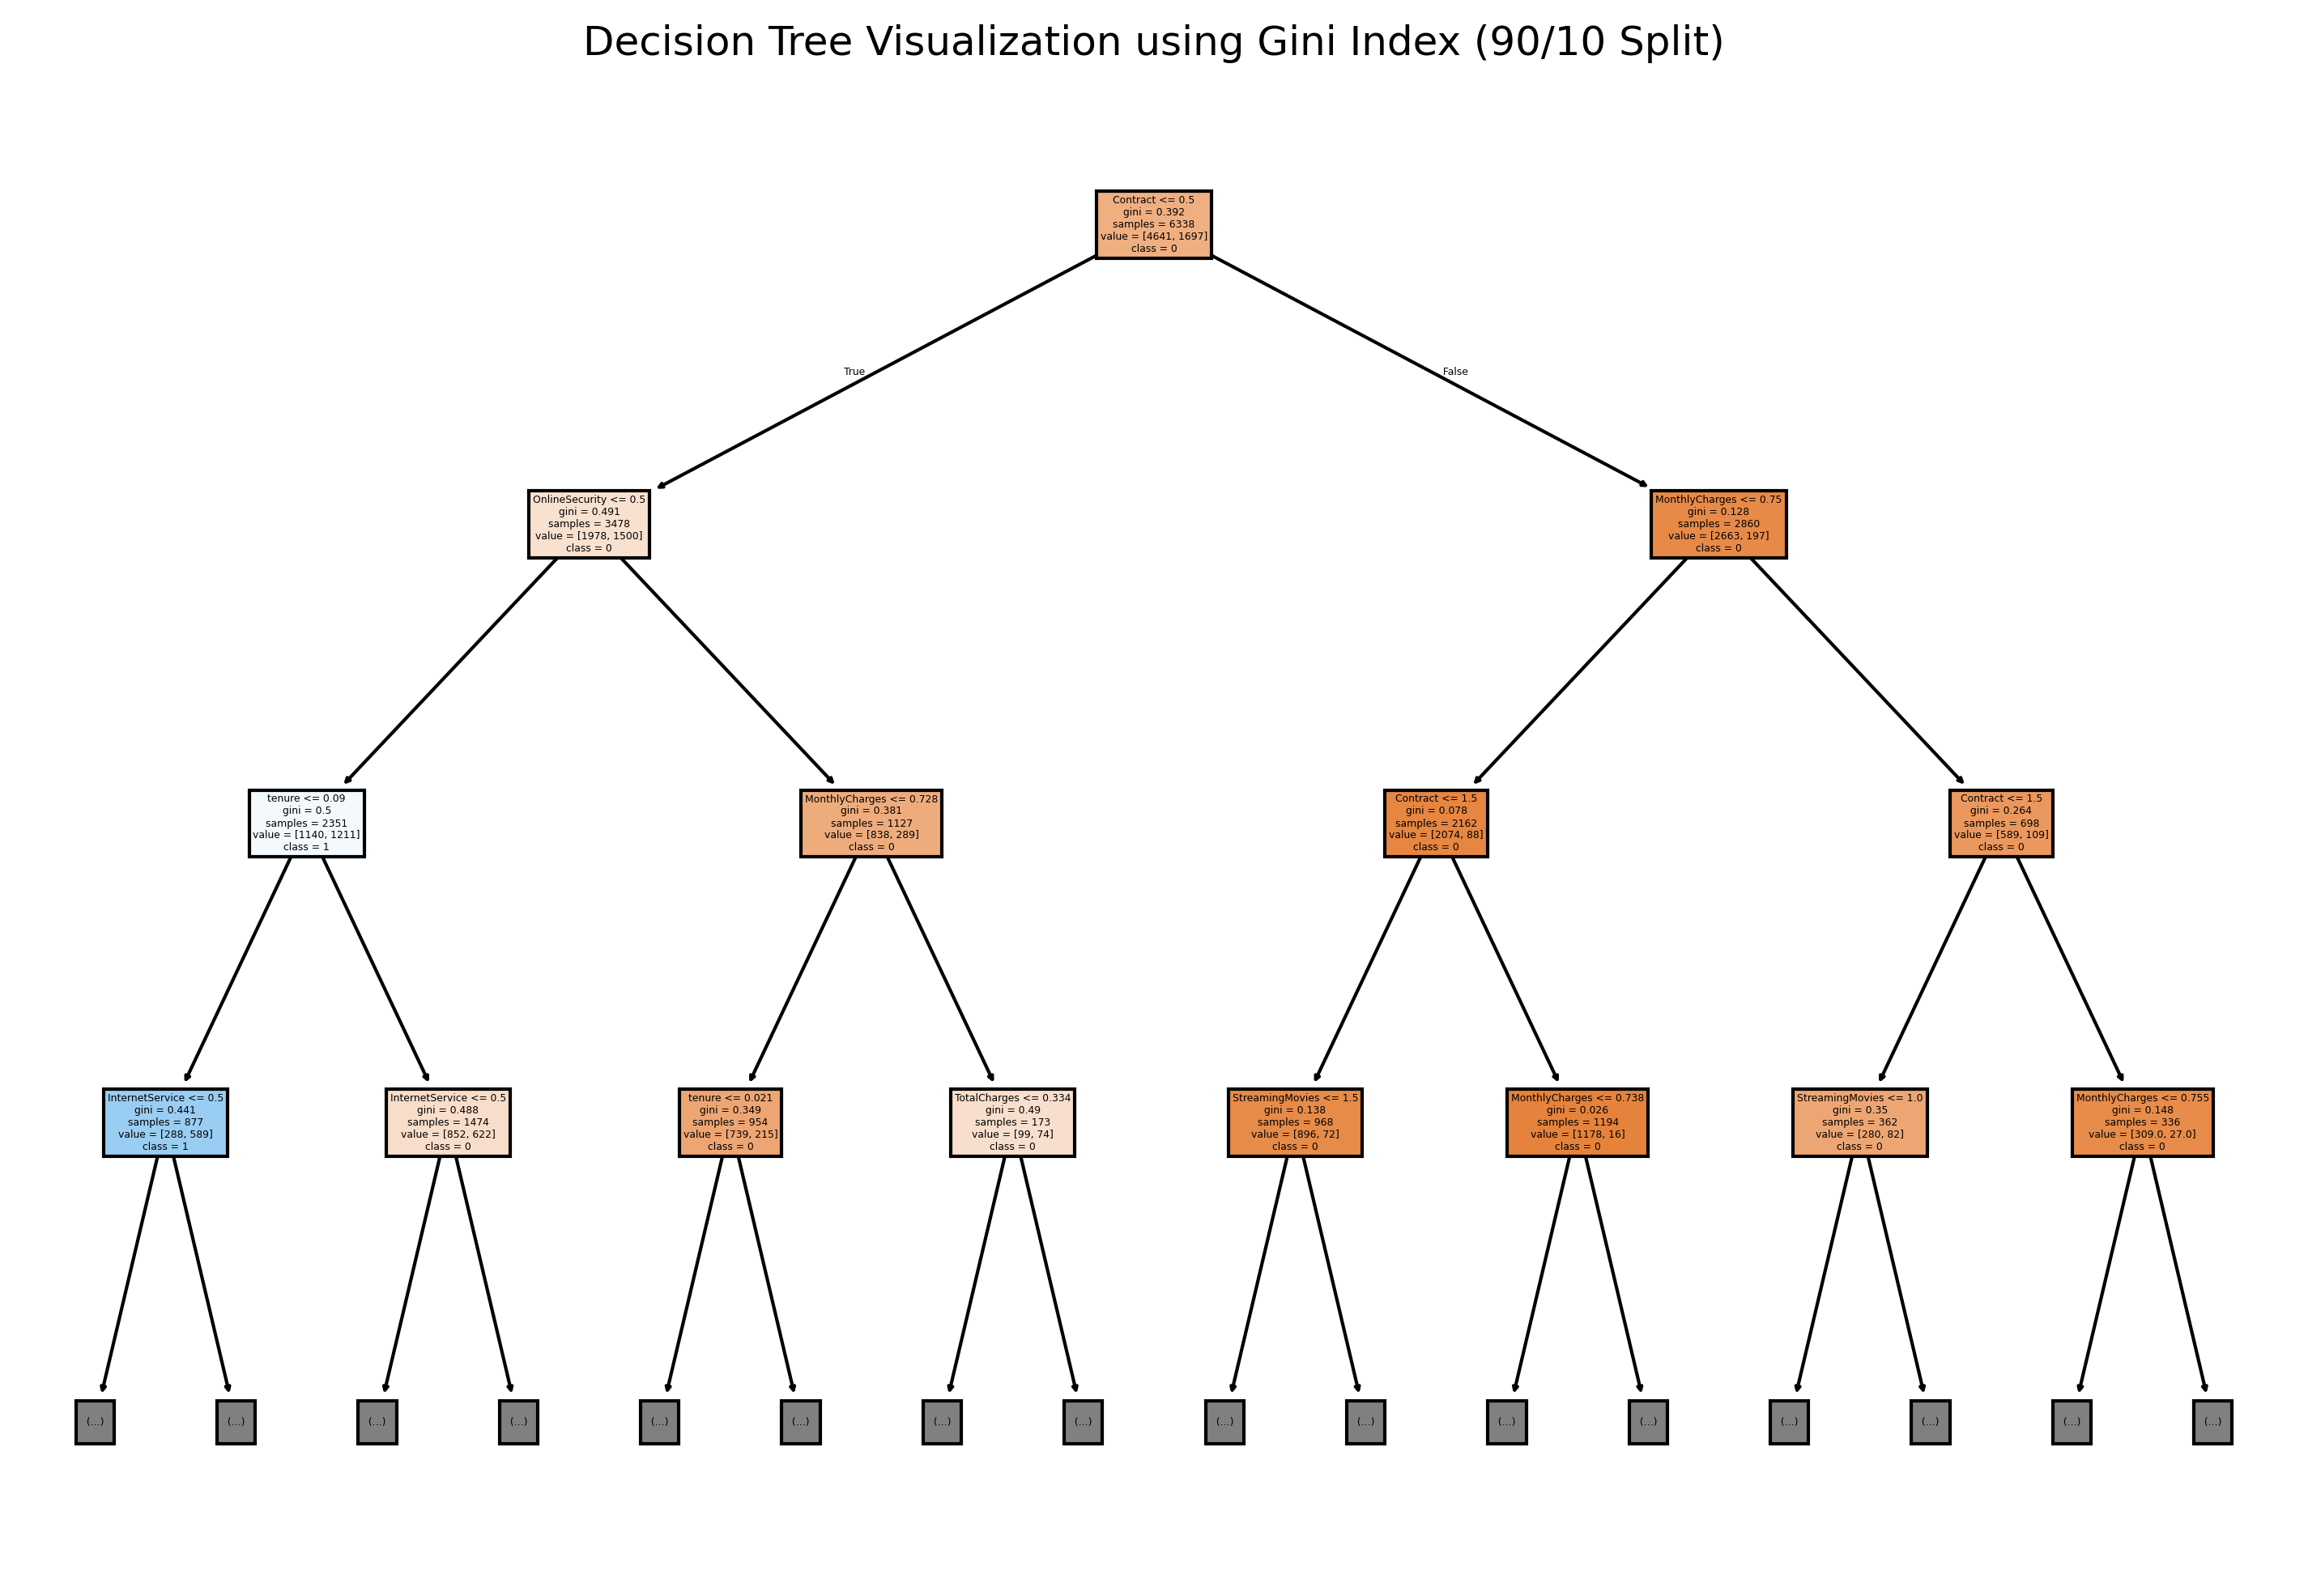

<Figure size 600x600 with 0 Axes>

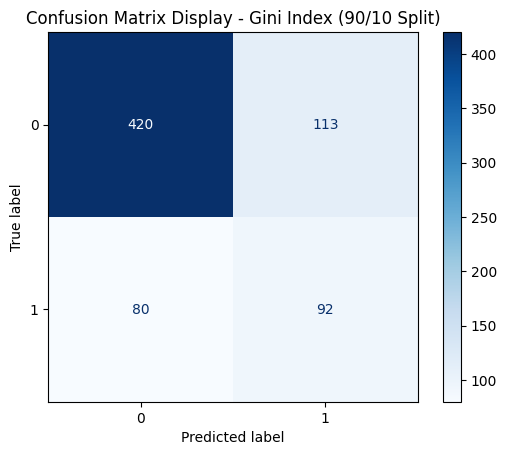


--- 80% Training / 20% Testing (Gini) ---
Accuracy: 0.7274662881476224


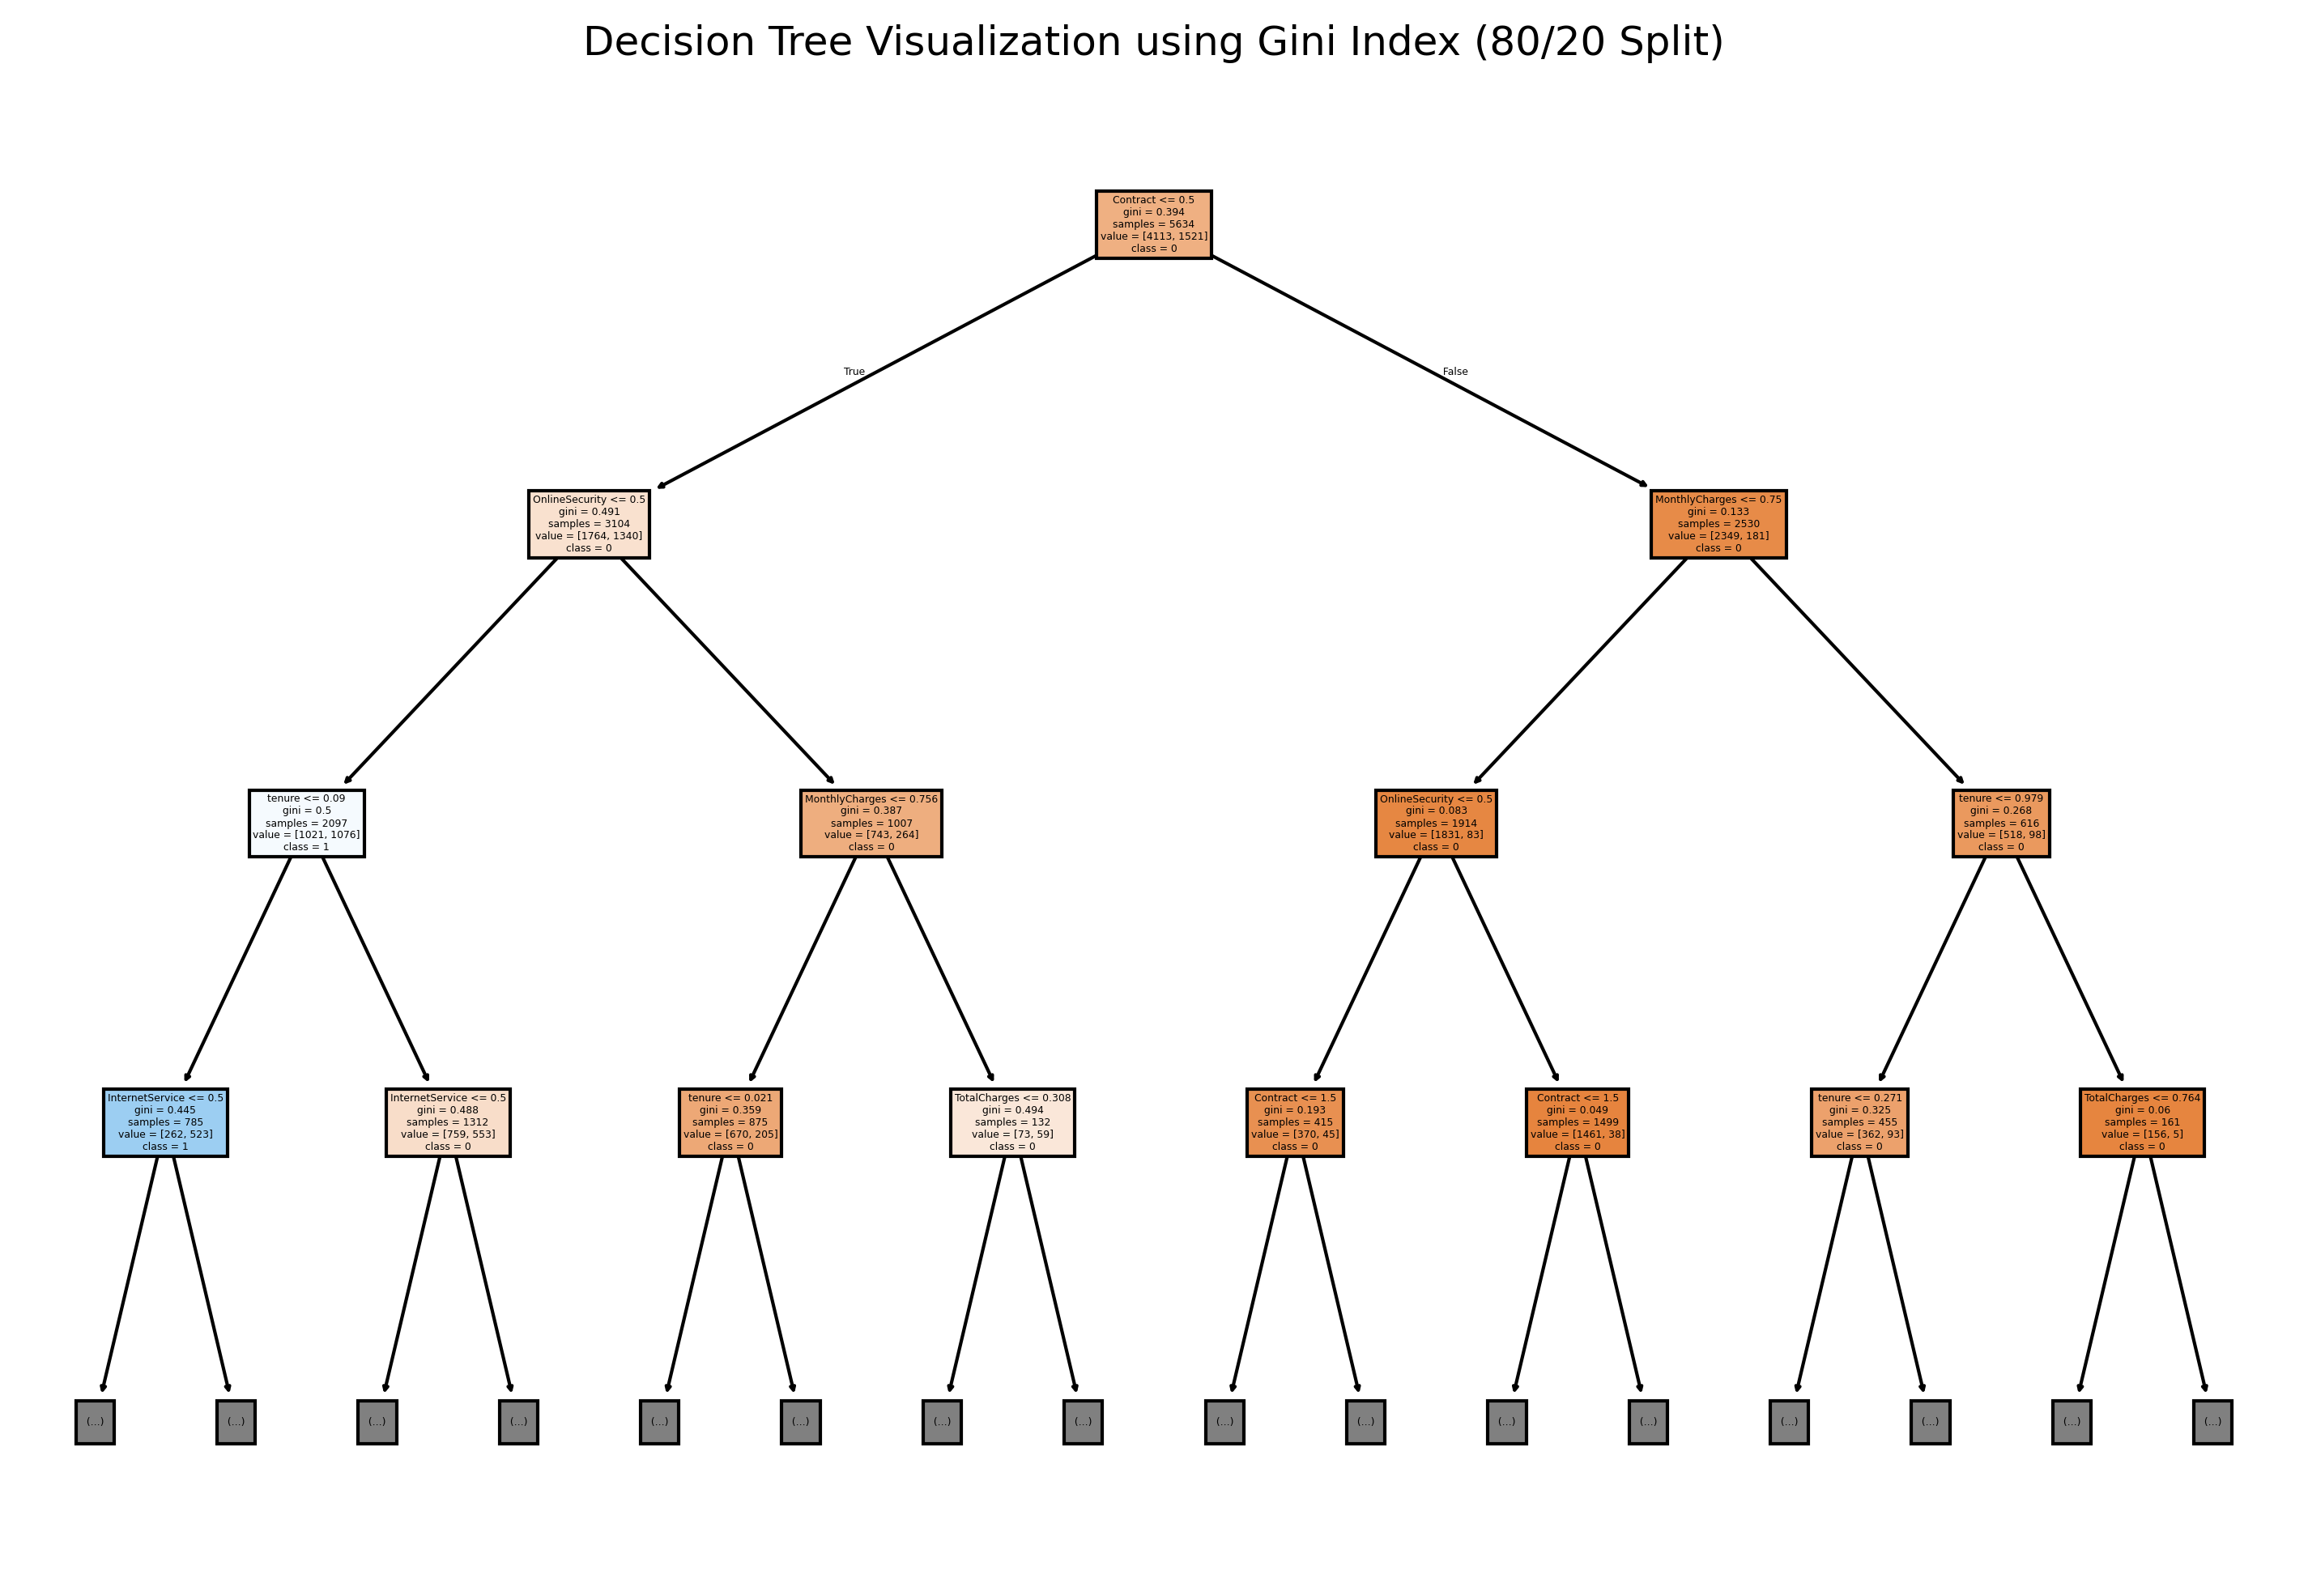

<Figure size 600x600 with 0 Axes>

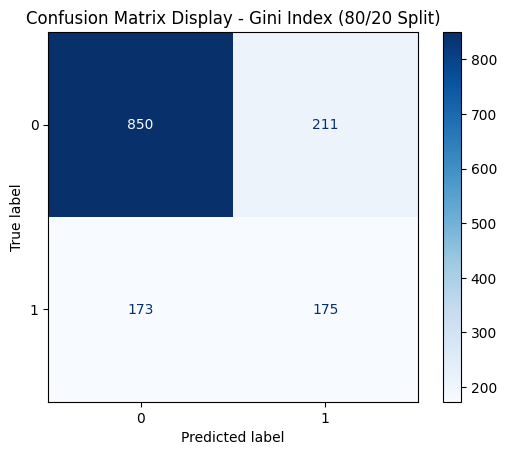


--- 70% Training / 30% Testing (Gini) ---
Accuracy: 0.7368670137245622


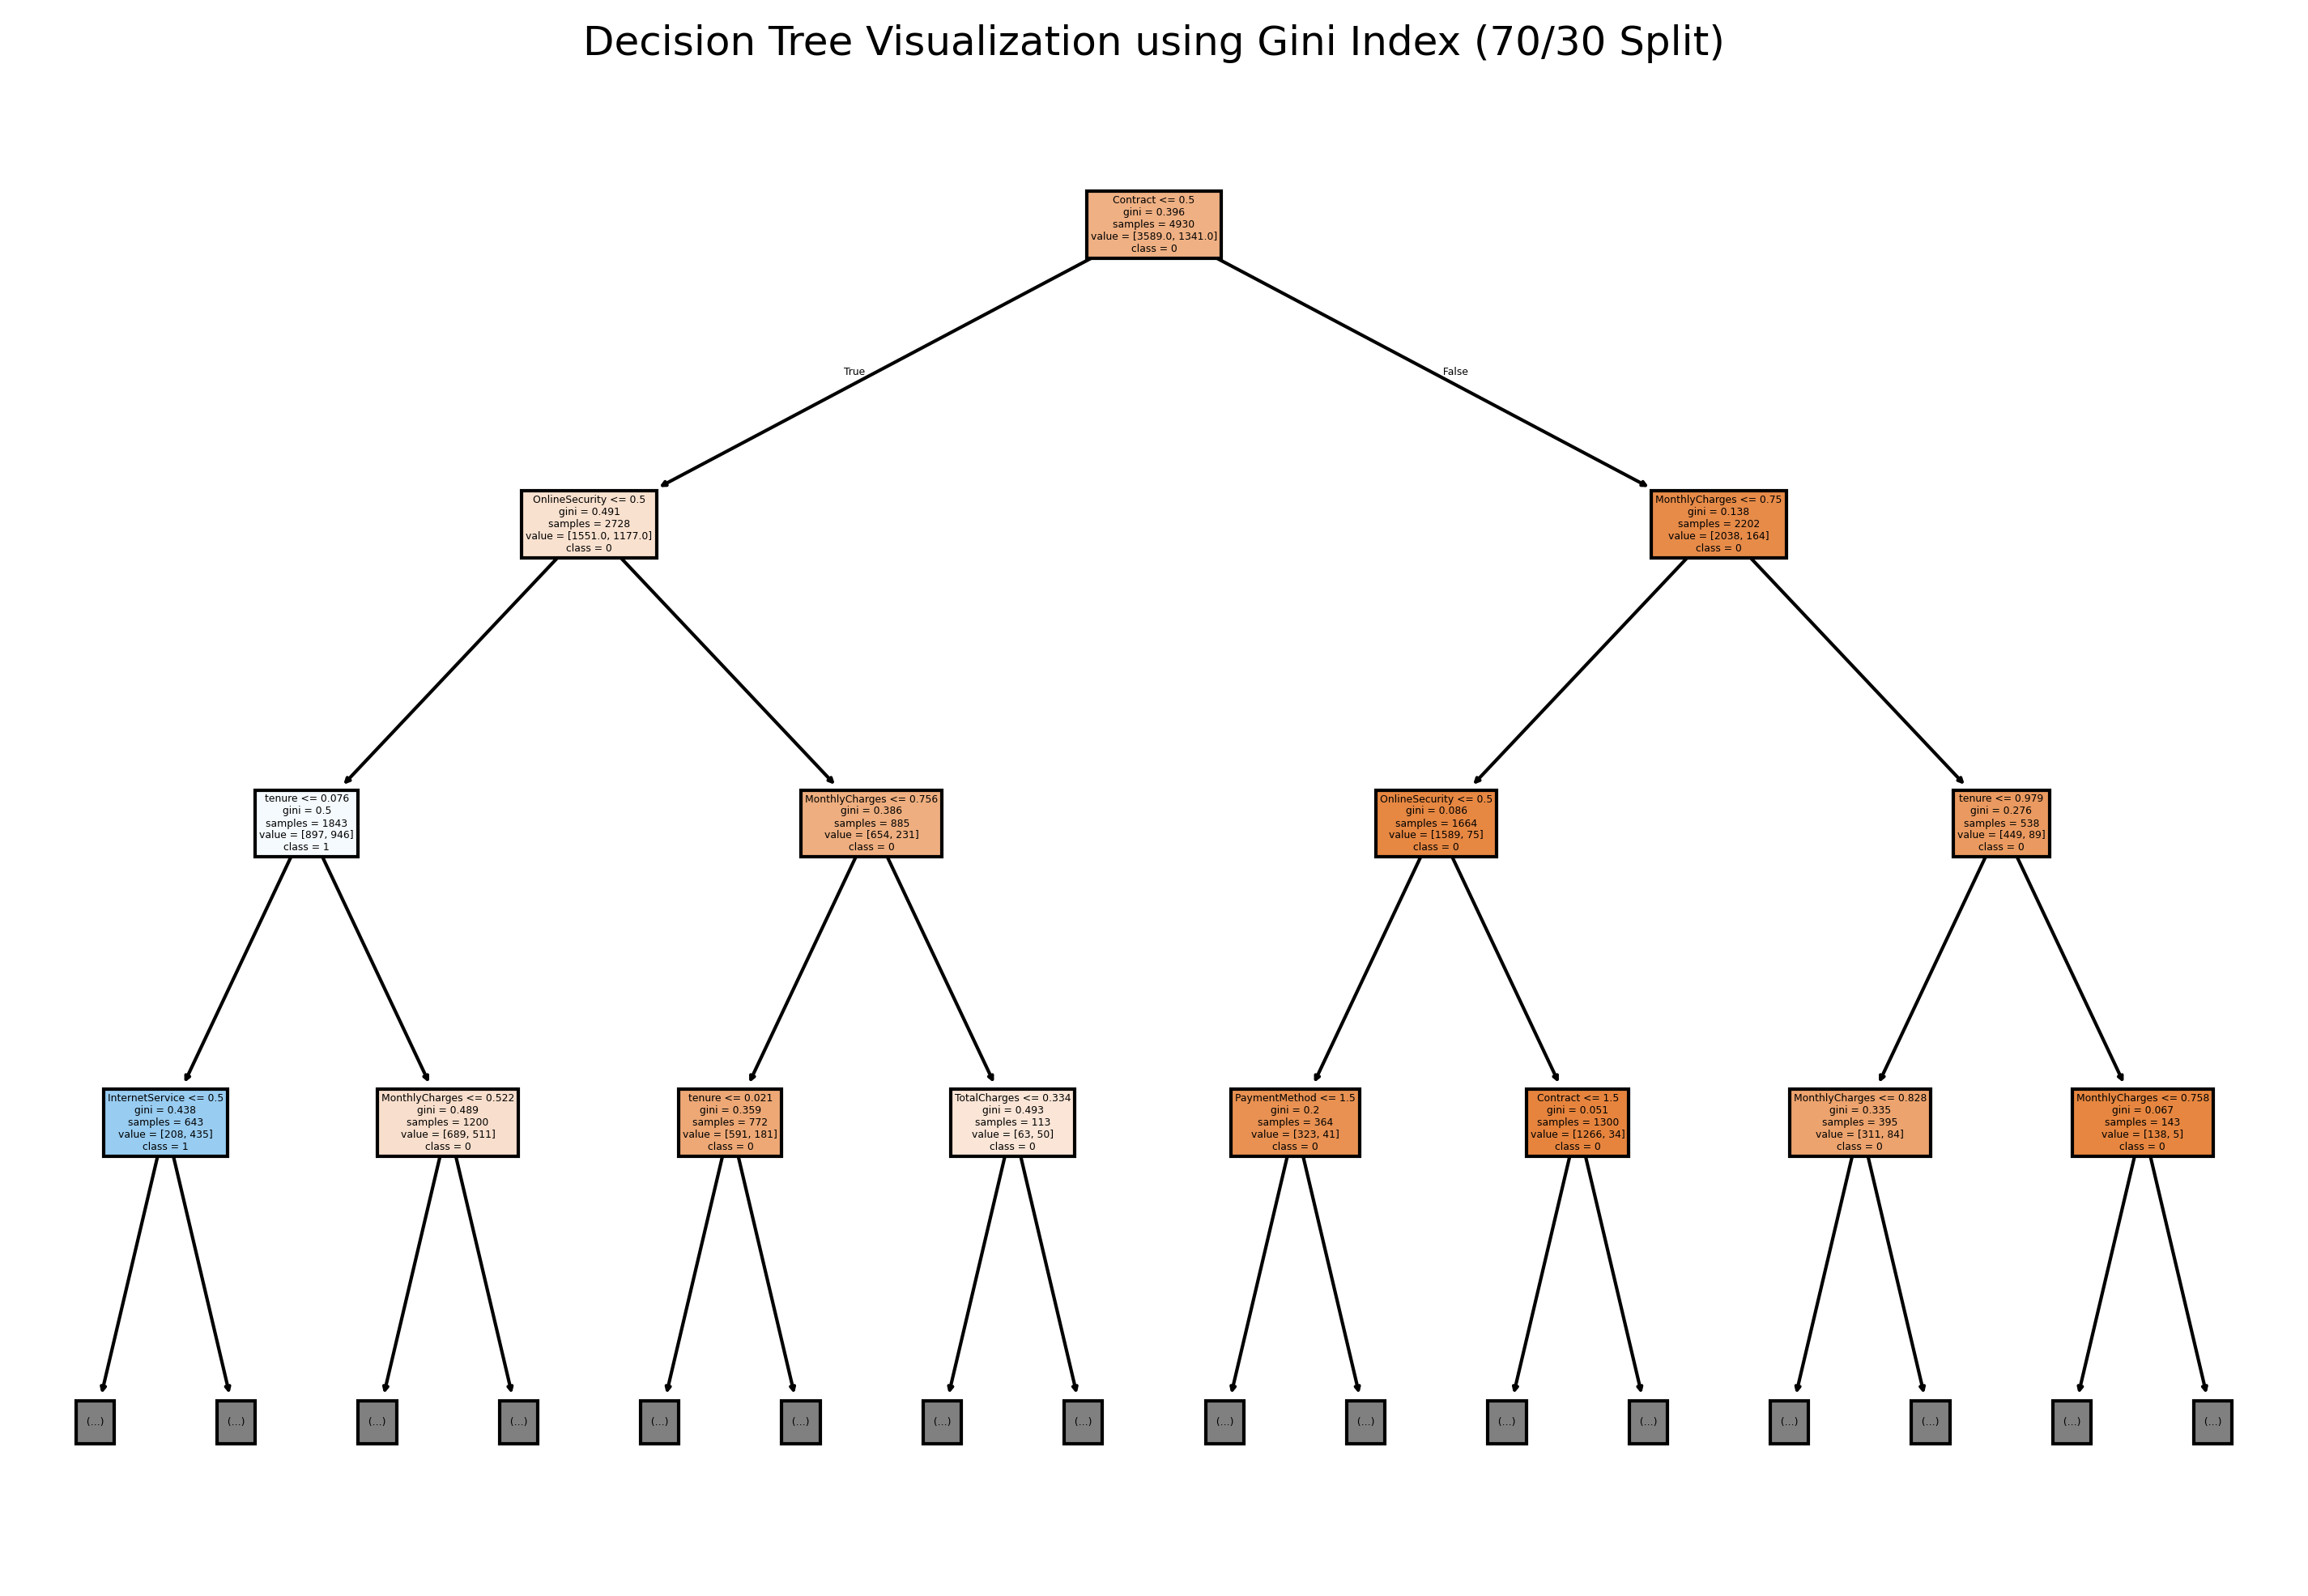

<Figure size 600x600 with 0 Axes>

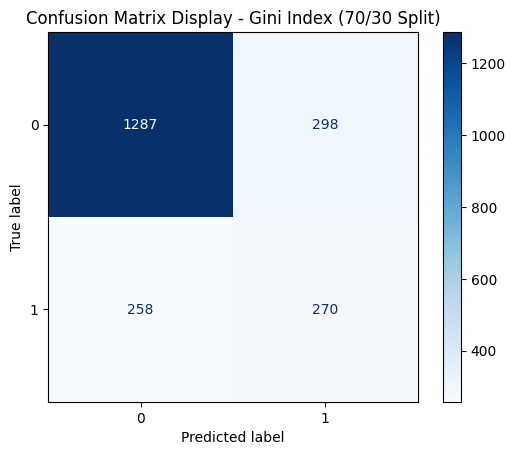

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn import tree

url = "https://raw.githubusercontent.com/LujainAldujain/Data_Mining_Project/refs/heads/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)

drop_cols = ['Churn', 'customerID']
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df['Churn']
cn = df['Churn'].unique().astype(str)
fn = X.columns.tolist()

X_train_90, X_test_90, y_train_90, y_test_90 = train_test_split(X, y, test_size=0.1, random_state=1)
clf_gini_90 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf_gini_90.fit(X_train_90, y_train_90)
y_pred_90 = clf_gini_90.predict(X_test_90)

print("--- 90% Training / 10% Testing (Gini) ---")
print("Accuracy:", metrics.accuracy_score(y_test_90, y_pred_90))
plt.figure(figsize=(12, 8) , dpi=300)
tree.plot_tree(clf_gini_90, feature_names=fn, class_names=cn, filled=True ,  max_depth=3)
plt.title("Decision Tree Visualization using Gini Index (90/10 Split)")
plt.show()

plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay.from_estimator(clf_gini_90, X_test_90, y_test_90, display_labels=cn, cmap=plt.cm.Blues)
plt.title("Confusion Matrix Display - Gini Index (90/10 Split)")
plt.show()

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(X, y, test_size=0.2, random_state=1)
clf_gini_80 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf_gini_80.fit(X_train_80, y_train_80)
y_pred_80 = clf_gini_80.predict(X_test_80)

print("\n--- 80% Training / 20% Testing (Gini) ---")
print("Accuracy:", metrics.accuracy_score(y_test_80, y_pred_80))
plt.figure(figsize=(12, 8) , dpi=300)
tree.plot_tree(clf_gini_80, feature_names=fn, class_names=cn, filled=True ,  max_depth=3)
plt.title("Decision Tree Visualization using Gini Index (80/20 Split)")
plt.show()

plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay.from_estimator(clf_gini_80, X_test_80, y_test_80, display_labels=cn, cmap=plt.cm.Blues)
plt.title("Confusion Matrix Display - Gini Index (80/20 Split)")
plt.show()

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(X, y, test_size=0.3, random_state=1)
clf_gini_70 = DecisionTreeClassifier(criterion="gini", random_state=42)
clf_gini_70.fit(X_train_70, y_train_70)
y_pred_70 = clf_gini_70.predict(X_test_70)

print("\n--- 70% Training / 30% Testing (Gini) ---")
print("Accuracy:", metrics.accuracy_score(y_test_70, y_pred_70))
plt.figure(figsize=(12, 8) , dpi=300)
tree.plot_tree(clf_gini_70, feature_names=fn, class_names=cn, filled=True ,  max_depth=3)
plt.title("Decision Tree Visualization using Gini Index (70/30 Split)")
plt.show()

plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay.from_estimator(clf_gini_70, X_test_70, y_test_70, display_labels=cn, cmap=plt.cm.Blues)
plt.title("Confusion Matrix Display - Gini Index (70/30 Split)")
plt.show()


#### **Gini Index Performance Summary Table**
|  | 90 % training set 10% testing set | 80 % training set 20% testing set | 70 % training set 30% testing set |
| :--- | :--- |  :--- | :--- |
| **Accuracy** | 72.62% |  72.75 % |  73.69 % |

#### **Discussion (Gini Index):**

- **Accuracy across partitions:** The 70% training / 30% testing split gave the highest accuracy (73.69%), followed by 80/20 (72.75%) and 90/10 (72.62%). The differences are small, so the model performs fairly consistently.
- **Confusion matrices:** In all three partitions, the model predicts class 0 much better than class 1. For example, in the 70/30 split, 1287 of 1585 class 0 records are correct, but only 270 of 528 class 1 records.
- **Key insight:** The overall accuracy (about 72% to 73%) looks acceptable, but it hides the fact that the model correctly identifies only about half of the class 1 records. The confusion matrices are therefore needed to understand the model's real performance.

###**6.2 Evaluation and Comparison for Entropy (Information Gain) Classification**

To evaluate the performance of the Decision Tree model using **Entropy (Information Gain)**, we tested the same three partition sizes for training and testing:

1. **90% Training / 10% Testing**
2. **80% Training / 20% Testing**
3. **70% Training / 30% Testing**

Below are the accuracy scores, confusion matrices, and visualizations for each partition.


--- 90/10 (Entropy) ---
Accuracy: 0.7134751773049646


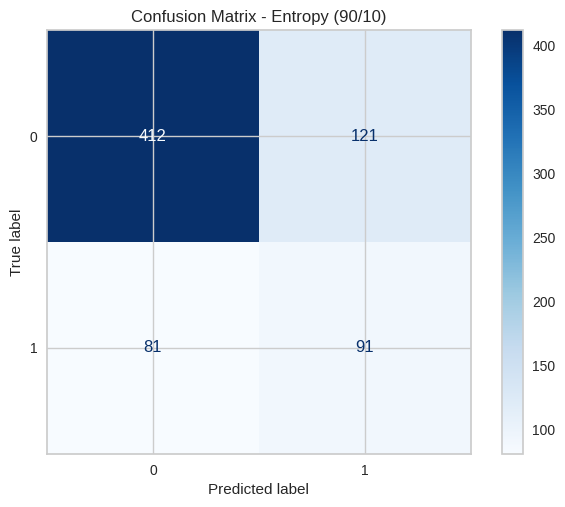

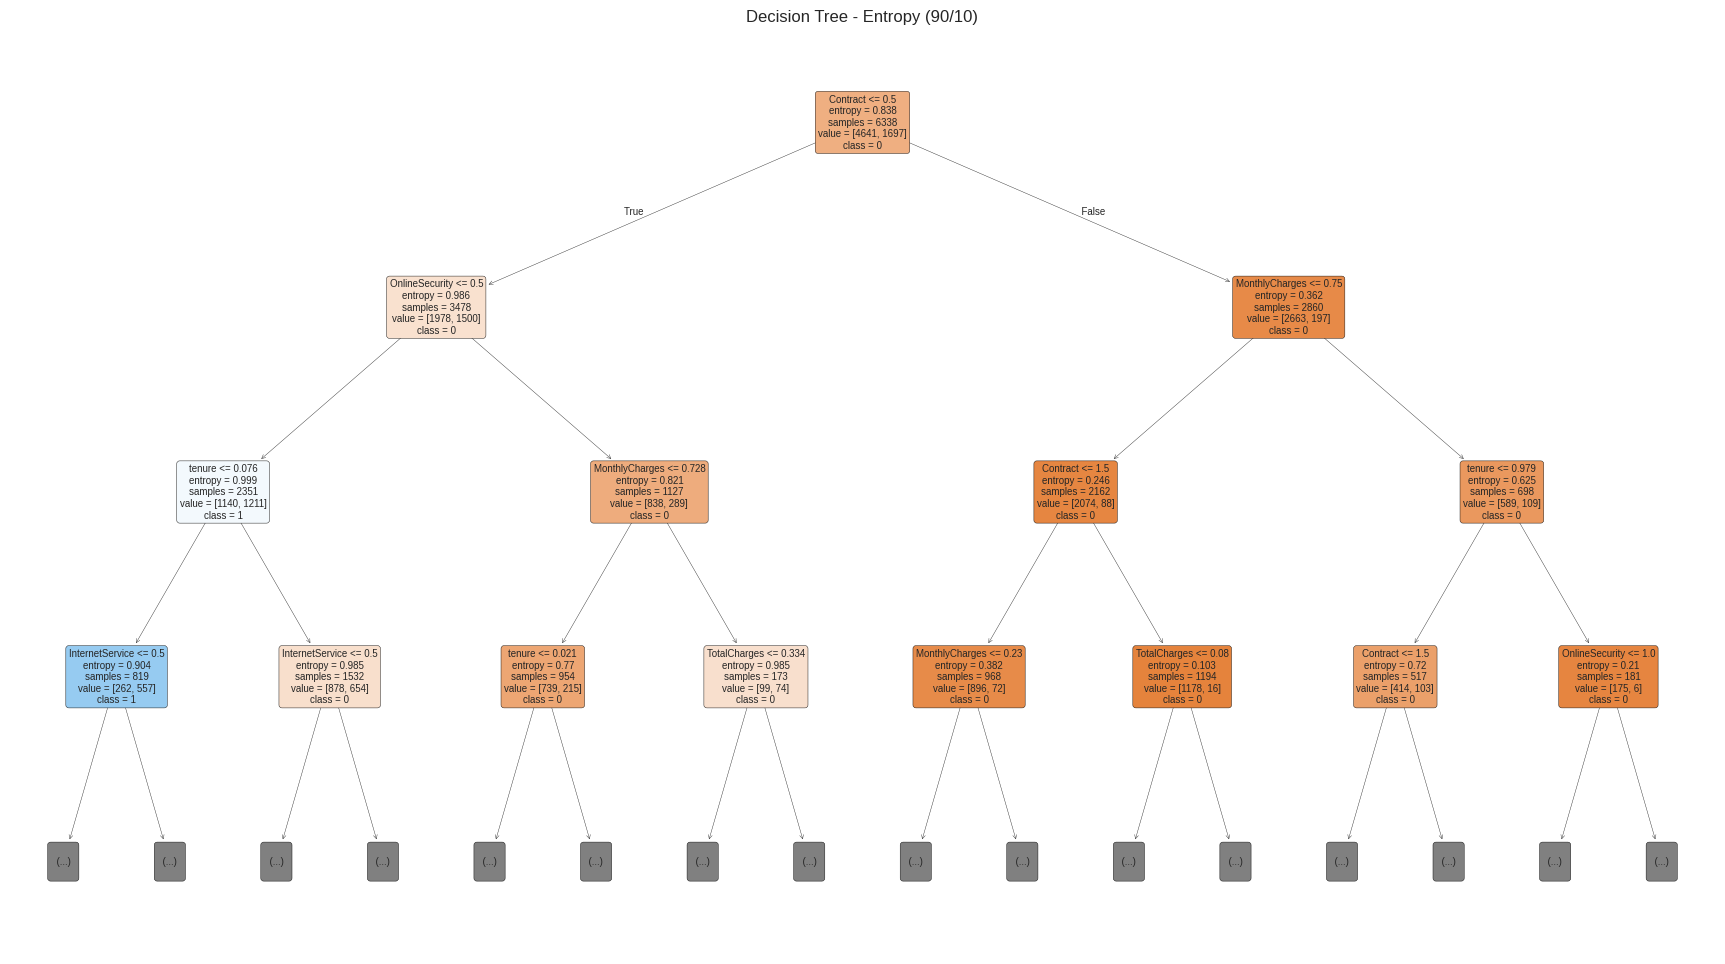


--- 80/20 (Entropy) ---
Accuracy: 0.7359829666430092


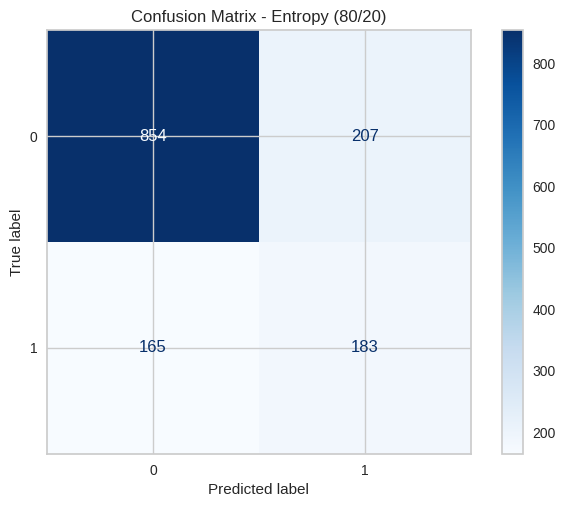

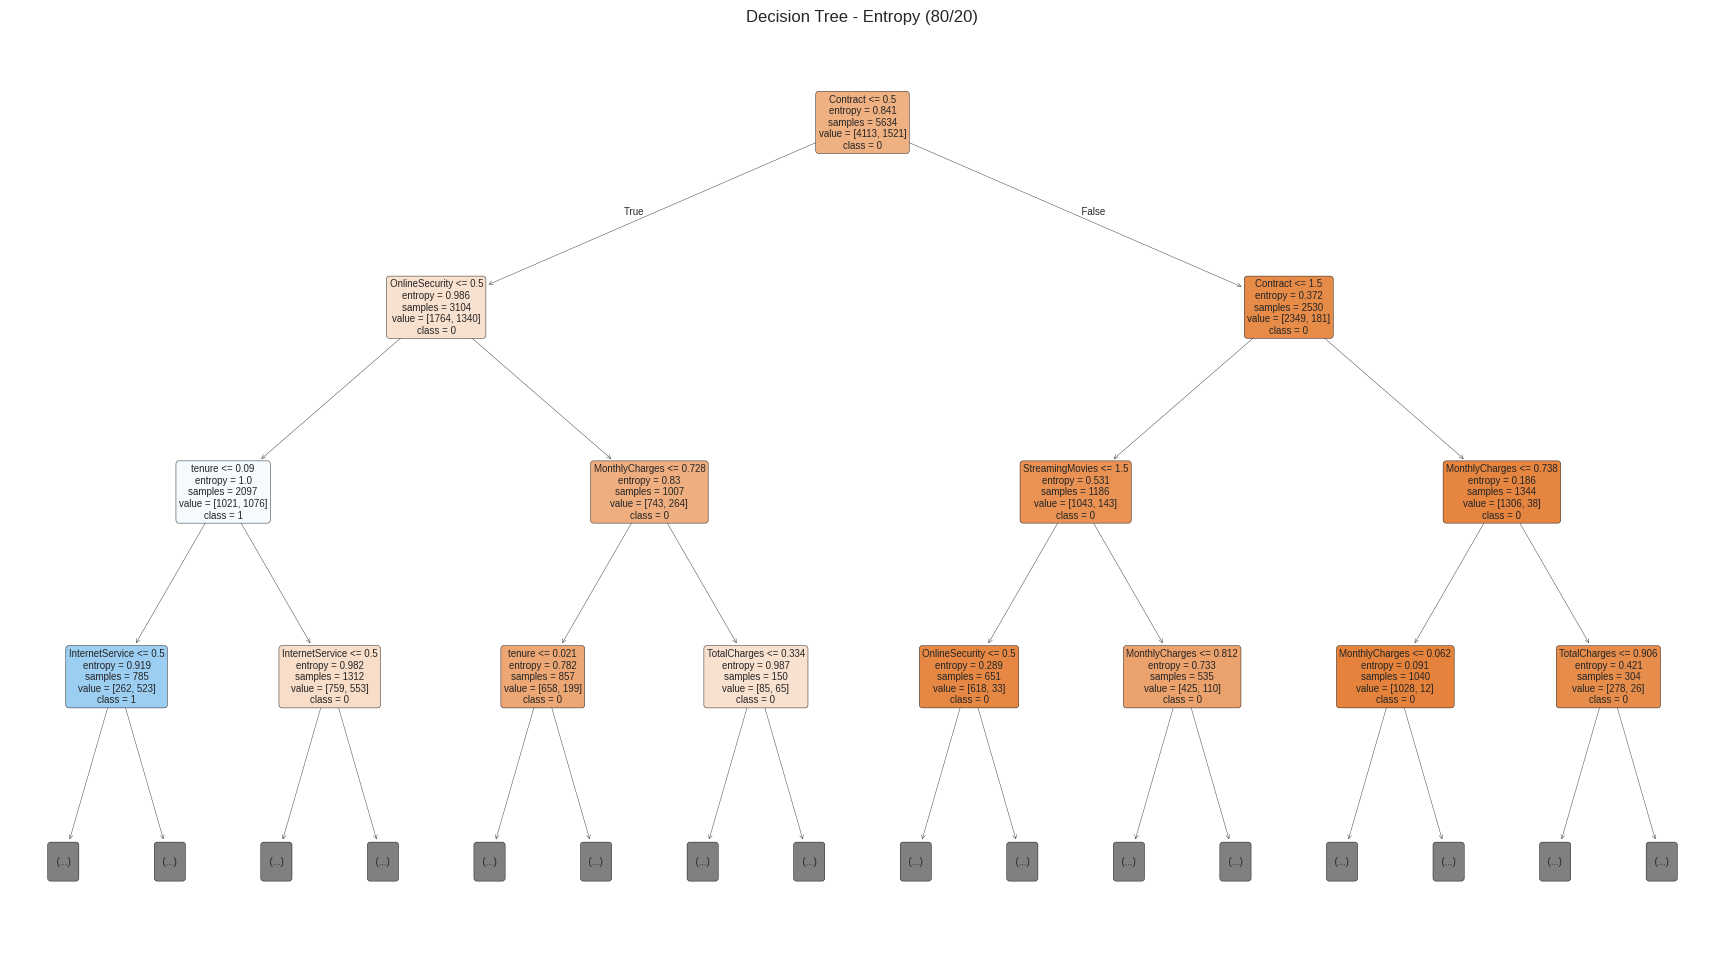


--- 70/30 (Entropy) ---
Accuracy: 0.7439659252247989


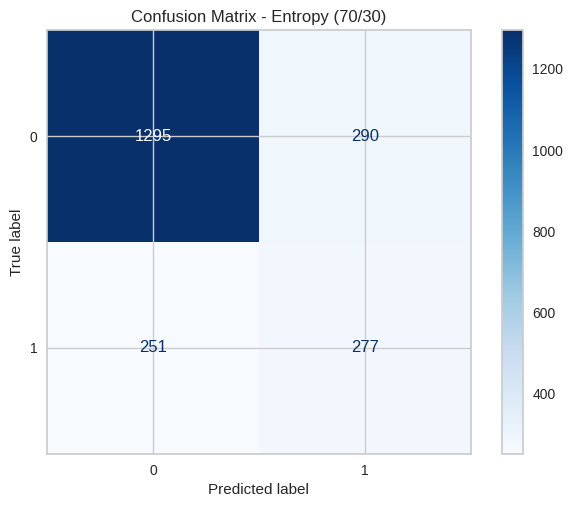

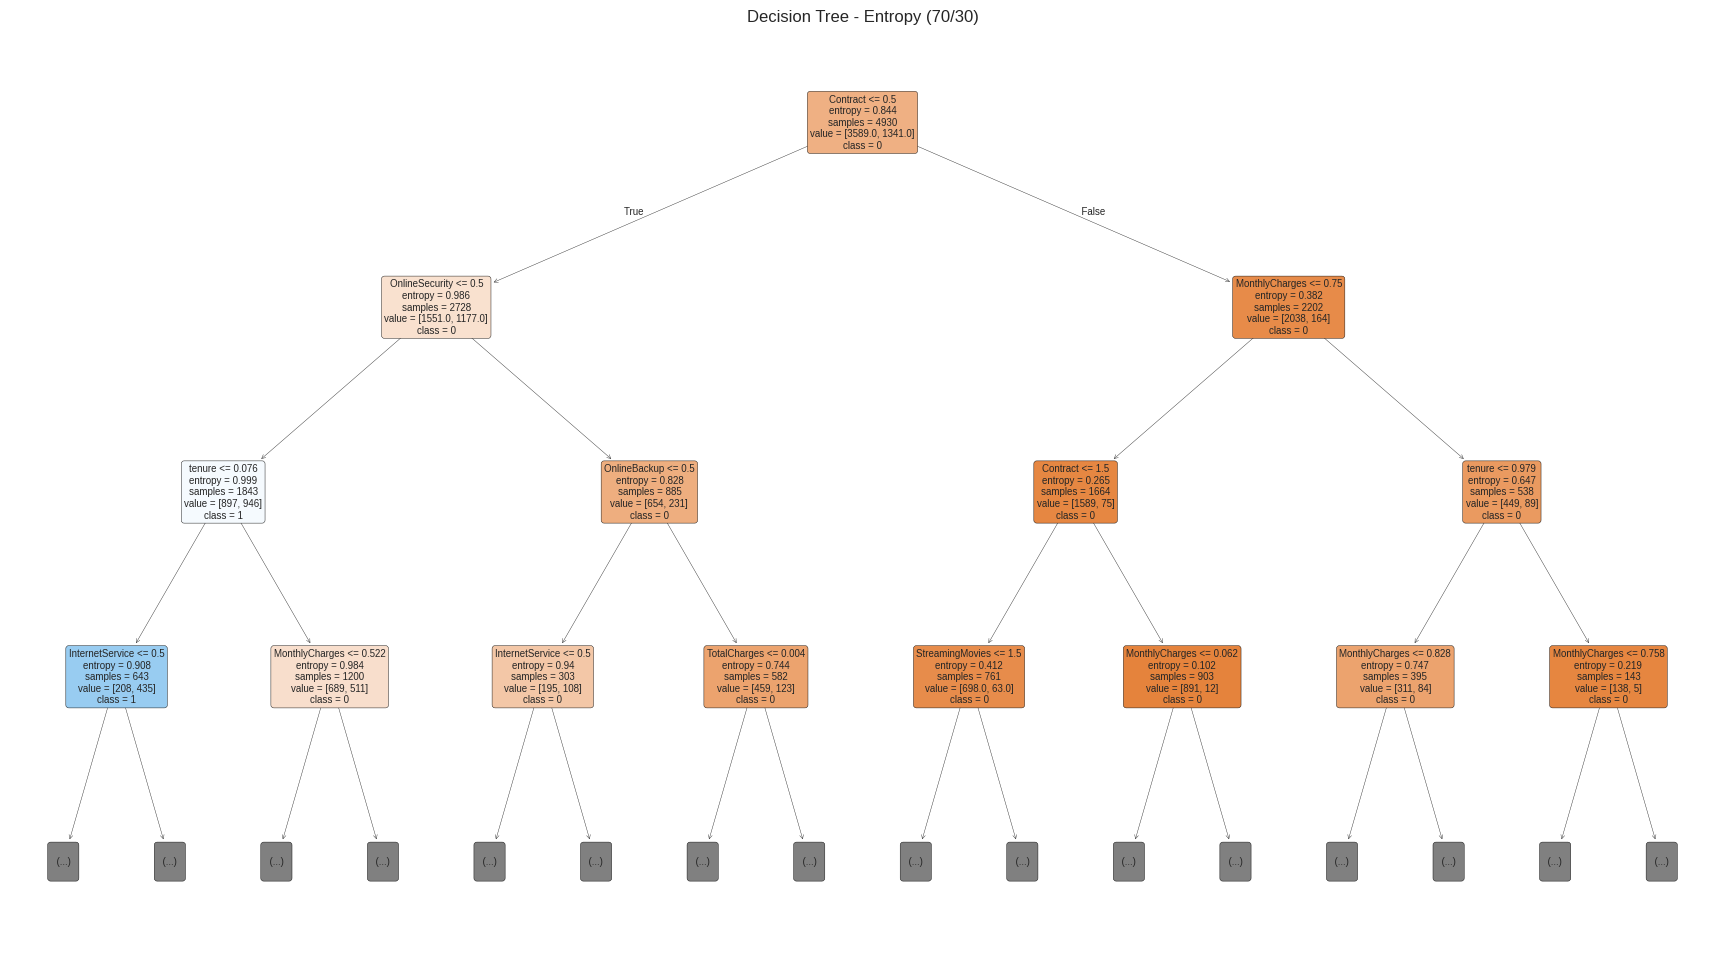

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

url = "https://raw.githubusercontent.com/LujainAldujain/Data_Mining_Project/refs/heads/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)

drop_cols = ['Churn', 'customerID']
X = df.drop(columns=[c for c in drop_cols if c in df.columns])
y = df['Churn']
cn = df['Churn'].unique().astype(str)
fn = X.columns.tolist()

splits = {"90/10": 0.1, "80/20": 0.2, "70/30": 0.3}
results = []

for name, ts in splits.items():
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=ts, random_state=1)

    clf = DecisionTreeClassifier(criterion="entropy", random_state=42)
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    acc = metrics.accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    print(f"\n--- {name} (Entropy) ---")
    print("Accuracy:", acc)

    ConfusionMatrixDisplay(cm, display_labels=clf.classes_).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - Entropy ({name})")
    plt.show()

    plt.figure(figsize=(22, 12))
    plot_tree(clf, feature_names=fn, class_names=[str(c) for c in clf.classes_],
              filled=True, rounded=True, fontsize=7, max_depth=3)
    plt.title(f"Decision Tree - Entropy ({name})")
    plt.show()

#### **Entropy (Information Gain)  Performance Summary Table**
|  | 90 % training set 10% testing set | 80 % training set 20% testing set | 70 % training set 30% testing set |
| :--- | :--- |  :--- | :--- |
| **Accuracy** | 71.35 % |  73.60 % |  74.40 % |

####**Discussion (Entropy / Information Gain):**

* **Accuracy across partitions:** The 70% training / 30% testing split gave the highest accuracy (74.40%), followed by 80/20 (73.60%) and 90/10 (71.35%). The differences are small, so the model performs fairly consistently.
* **Confusion matrices:** In all three partitions, the model predicts class 0 much better than class 1. For example, in the 70/30 split, 1295 of 1585 class 0 records are correct, but only 277 of 528 class 1 records.
* **Key insight:** The overall accuracy (about 71% to 74%) looks acceptable, but it hides the fact that the model correctly identifies only about half of the class 1 records. The confusion matrices are therefore needed to understand the model's real performance.

###**6.3 Comparison: Information Gain (Entropy) vs Gini Index**

To compare the two attribute selection measures, a Decision Tree was trained with each measure on the same preprocessed dataset. Both used the same three partitions and the same random split settings, so for each partition the two trees were trained and tested on exactly the same records. This means any difference in accuracy comes from the attribute selection measure and not from the data.

| | 90% training / 10% testing | 80% training / 20% testing | 70% training / 30% testing | Average |
|---|---|---|---|---|
| **Accuracy (IG)** | 71.35% | 73.60% | 74.40% | 73.11% |
| **Accuracy (Gini)** | 72.62% | 72.75% | 73.69% | 73.02% |


**Which algorithm performs best for each partition:**

For the 90% training / 10% testing partition, the Gini Index performed best, with an accuracy of 72.62% compared to 71.35% for Information Gain. This is a gap of 1.27 percentage points, which is the largest gap of the three partitions and the only one in favor of Gini. It is also the partition with the smallest testing set (705 records), so each individual prediction has more influence on the accuracy and the result is the least reliable of the three.

For the 80% training / 20% testing partition, Information Gain performed best, with an accuracy of 73.60% compared to 72.75% for the Gini Index, a gap of 0.85 percentage points. Here Information Gain improved by 2.25 percentage points compared with its own result on the 90/10 partition, while Gini improved by only 0.13.

For the 70% training / 30% testing partition, Information Gain again performed best, with an accuracy of 74.40% compared to 73.69% for the Gini Index, a gap of 0.71 percentage points. This partition has the largest testing set (2,113 records), so it gives the most reliable estimate of the three, and both measures reached their highest accuracy here.

**Which algorithm performs best overall across all partitions:**

Information Gain performed best overall. It achieved the higher accuracy in two of the three partitions (80/20 and 70/30), and its average accuracy across the three partitions (73.11%) is slightly higher than that of the Gini Index (73.02%). However, the overall difference is only 0.09 percentage points, which is very small. In practice, the two measures perform almost the same on this dataset, and the choice between them would not change the quality of the model in a meaningful way.

**What these results indicate:**

Upon comparing the performance of both Decision Tree models implemented using different splitting criteria (Gini Index and Entropy), a significant performance gap was observed between the training accuracy (99.80%) and the testing accuracy (71%–74%) in both models. This indicates that both criteria suffer from overfitting, as the trees grew excessively deep and captured data noise rather than general patterns.

The attribute selection measure has only a small effect on accuracy for this dataset, since the difference between the two measures never exceeds 1.27 percentage points in any partition. Both measures reached their highest accuracy with the 70% training / 30% testing partition, and for both of them the accuracy was lower with the 90% training / 10% testing partition, even though it uses the most training data.

The two measures differ in how stable they are across partitions. The accuracy of the Gini Index stayed between 72.62% and 73.69%, a range of 1.07 percentage points, while the accuracy of Information Gain varied between 71.35% and 74.40%, a range of 3.05 percentage points. Gini was therefore more stable, while Information Gain was more sensitive to the partition size, performing worst on the 90/10 partition and best on the 70/30 partition.

### 6.4 Evaluation and Comparison for K-Means Clustering

To evaluate the performance of K-Means clustering, we apply the algorithm to the preprocessed Telco Customer Churn dataset using different values of K.

We use two evaluation methods:

1. **Silhouette Score:** To measure how well the customers are grouped within their clusters and how well the clusters are separated.
2. **Elbow Method (WCSS):** To evaluate cluster compactness and help identify an appropriate number of clusters.

The results will be compared to determine the optimal K and understand the characteristics of the resulting customer groups.

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler

url = "https://raw.githubusercontent.com/LujainAldujain/Data_Mining_Project/refs/heads/main/Dataset/Preprocessed_dataset.csv"

df = pd.read_csv(url)

features = df.drop(columns=['Churn', 'customerID'])

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

scaled_data = pd.DataFrame(
    scaled_features,
    columns=features.columns
)

print("Scaled DataFrame:")
print(scaled_data.head())

Scaled DataFrame:
     gender  SeniorCitizen   Partner  Dependents    tenure  PhoneService  \
0 -1.009559      -0.439916  1.034530   -0.654012 -1.277445     -3.054010   
1  0.990532      -0.439916 -0.966622   -0.654012  0.066327      0.327438   
2  0.990532      -0.439916 -0.966622   -0.654012 -1.236724      0.327438   
3  0.990532      -0.439916 -0.966622   -0.654012  0.514251     -3.054010   
4 -1.009559      -0.439916 -0.966622   -0.654012 -1.236724      0.327438   

   MultipleLines  InternetService  OnlineSecurity  OnlineBackup  \
0       0.062723        -1.183234       -0.918838      1.242550   
1      -0.991588        -1.183234        1.407321     -1.029919   
2      -0.991588        -1.183234        1.407321      1.242550   
3       0.062723        -1.183234        1.407321     -1.029919   
4      -0.991588         0.172250       -0.918838     -1.029919   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  Contract  \
0         -1.027910    -0.925262    -1.113495 

#### Data Preparation

The preprocessed Telco Customer Churn dataset was used for K-Means clustering.

First, we excluded the `customerID` attribute because it is a unique identifier that does not represent customer characteristics. We also excluded the `Churn` attribute because K-Means is an unsupervised learning algorithm that groups customers based on similarities without using the target class label.

Next, we applied `StandardScaler` to standardize the features so that attributes with different numerical scales would not disproportionately influence the distance calculations.

Finally, the scaled features were stored in a new DataFrame to be used for K-Means clustering.

**Purpose:** This preparation allows K-Means to group customers based on their characteristics rather than customer identifiers or known churn labels.

#### Applying K-Means Clustering

K-Means clustering is applied to group customers based on similarities in their characteristics.

We initially selected K=2, K=3, and K=4 to investigate how different numbers of clusters affect customer segmentation.

K=2 was chosen to examine a simple division of customers into two groups. K=3 was selected to investigate whether adding a third cluster provides a more detailed segmentation. K=4 was included to examine the effect of dividing customers into four groups.

These three consecutive values allow us to compare different levels of customer segmentation, starting from a simple grouping and gradually increasing the number of clusters.

The selected values will be evaluated using the Silhouette Score and Elbow Method to determine the most suitable number of clusters.


In [ ]:
import numpy as np
from sklearn.cluster import KMeans

np.random.seed(42)

k_values = [2, 3, 4]

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_result = kmeans.fit(scaled_features)

    print("K =", k)
    print("Cluster Centers:")
    print(kmeans_result.cluster_centers_)
    print("Cluster Labels:")
    print(kmeans_result.labels_)
    print()

K = 2
Cluster Centers:
[[-0.01433739  0.05840344  0.48727627  0.21191219  0.9648196   0.05265639
   0.52043849 -0.15970504  0.35213409  0.4646824   0.54549254  0.40780479
   0.49285405  0.50239203  0.68816465  0.10191104 -0.46583061  0.54891762
   0.98486553]
 [ 0.00888667 -0.03619992 -0.30202611 -0.13134852 -0.59801951 -0.03263776
  -0.3225809   0.09898921 -0.21826158 -0.28802186 -0.33811003 -0.25276769
  -0.30548336 -0.31139525 -0.42654179 -0.06316703  0.28873355 -0.34023298
  -0.61044448]]
Cluster Labels:
[1 1 1 ... 1 1 0]

K = 3
Cluster Centers:
[[-1.33397321e-03  7.51356621e-02  4.48743002e-01  1.56051375e-01
   9.38703804e-01  1.88429051e-02  5.21572717e-01 -3.90832852e-01
   4.06462039e-01  5.32831222e-01  6.28175795e-01  4.72371438e-01
   5.72050857e-01  5.74672744e-01  6.18602039e-01  1.61421722e-01
  -4.31742778e-01  8.04622913e-01  1.17447252e+00]
 [ 1.30536854e-02 -3.50705123e-01  1.00846340e-02  2.83384585e-01
  -8.06964602e-02  3.09996924e-01 -5.22552437e-01  1.48753267e+

#### K-Means Clustering Description

K-Means clustering was applied to the standardized Telco Customer Churn dataset using three different numbers of clusters: K = 2, K = 3, and K = 4.

For each value of K, the algorithm assigned customers to clusters based on their similarity and calculated the corresponding cluster centers.

The cluster centers represent the average feature values within each cluster, while the cluster labels indicate the group assigned to each customer.

The parameter `random_state=42` was used to ensure reproducible results, and `n_init=10` was used to run K-Means with multiple initializations and retain the best solution based on inertia.

These clustering results will be evaluated using Silhouette Score and WCSS to determine which K provides the most suitable customer segmentation.

#### Silhouette Score Evaluation

The Silhouette Score is used to evaluate the quality of the clusters generated by K-Means.

It measures how similar customers are to other customers within the same cluster compared to customers in different clusters.

The score ranges from -1 to 1, where higher values indicate better cluster cohesion and separation.

We calculate the average Silhouette Score for different K values to evaluate the clustering performance and help determine the optimal number of clusters.

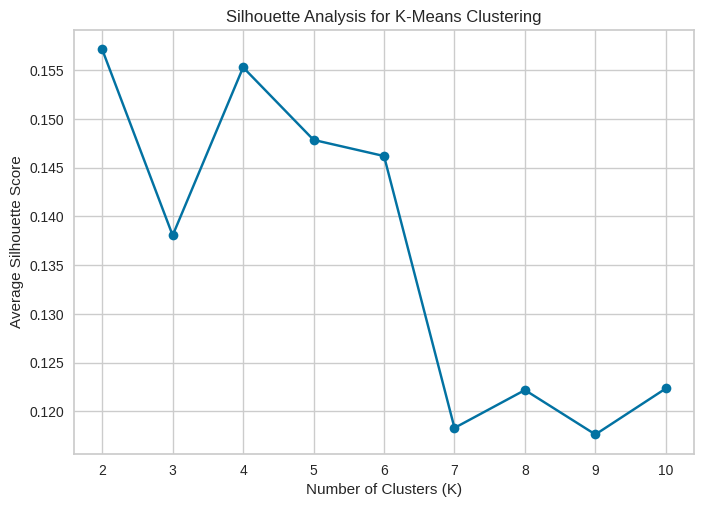

K = 2 Silhouette Score = 0.1571
K = 3 Silhouette Score = 0.1381
K = 4 Silhouette Score = 0.1553
K = 5 Silhouette Score = 0.1479
K = 6 Silhouette Score = 0.1462
K = 7 Silhouette Score = 0.1183
K = 8 Silhouette Score = 0.1222
K = 9 Silhouette Score = 0.1176
K = 10 Silhouette Score = 0.1224


In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 11)
silhouette_avg_values = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_result = kmeans.fit(scaled_features)
    silhouette_avg = silhouette_score(
        scaled_features,
        kmeans_result.labels_
    )
    silhouette_avg_values.append(silhouette_avg)

plt.plot(k_values, silhouette_avg_values, marker='o')
plt.title('Silhouette Analysis for K-Means Clustering')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Score')
plt.show()

for k, score in zip(k_values, silhouette_avg_values):
    print("K =", k, "Silhouette Score =", round(score, 4))

#### Silhouette Score Results and Description

The Silhouette Score was calculated for K values ranging from 2 to 10 to evaluate the quality of customer segmentation.

For each K value, K-Means clustering was applied to the standardized dataset, and the average Silhouette Score was calculated using all 7,043 customer records.

The results were visualized using a line plot to compare clustering performance across different numbers of clusters.

A higher Silhouette Score indicates better cluster cohesion and separation, while lower values suggest that the clusters may overlap.

This evaluation helps identify suitable K values for further comparison using the Elbow Method.


#### Silhouette Score Results Discussion

The Silhouette Score was calculated for K values ranging from 2 to 10 using all 7,043 customer records.

The results show that **K=2 achieved the highest Silhouette Score of 0.1571**, followed very closely by **K=4 with a score of 0.1553**. In comparison, K=3 achieved a lower score of 0.1381.

For larger values of K, the scores generally decreased. K=9 achieved the lowest score of 0.1176.

The small difference of 0.0018 between K=2 and K=4 indicates that both configurations have similar average cluster cohesion and separation.

However, all Silhouette Scores are relatively low, suggesting that the clusters are not strongly separated and that some overlap exists between customer groups.

Based on the Silhouette Score, **K=2 is the best-performing configuration**, while K=4 remains a competitive alternative. The Elbow Method and cluster interpretability will also be considered before selecting the optimal K.


#### Elbow Method (WCSS)

The Elbow Method is used to determine a suitable number of clusters by calculating the Within-Cluster Sum of Squares (WCSS) for different values of K.

WCSS measures the total squared distance between data points and their assigned cluster centers. Lower WCSS values indicate more compact clusters.

The optimal K is typically identified near the elbow point, where increasing the number of clusters produces smaller improvements in WCSS.


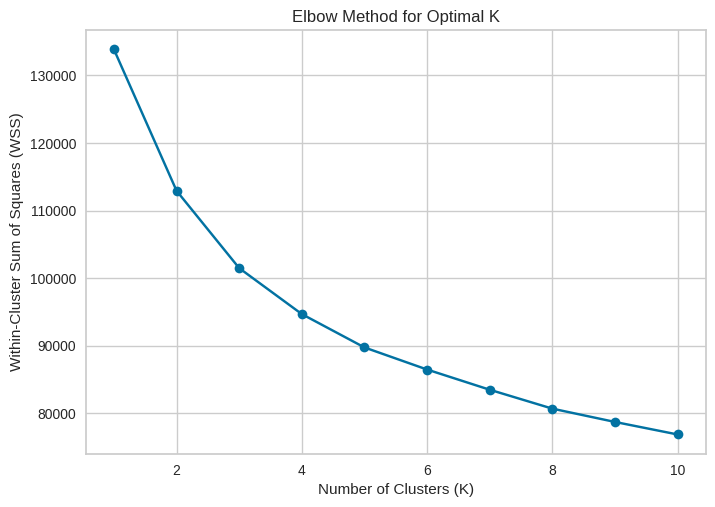

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wss_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_features)
    wss_values.append(kmeans.inertia_)

plt.plot(k_values, wss_values, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WSS)')
plt.title('Elbow Method for Optimal K')
plt.show()

#### Elbow Method Description

The Elbow Method was applied to the standardized Telco Customer Churn dataset using K values ranging from 1 to 10.

For each K value, K-Means clustering was performed, and the Within-Cluster Sum of Squares (WCSS) was calculated using the `inertia_` attribute.

The WCSS values were plotted against the number of clusters to examine how cluster compactness changes as K increases.

As the number of clusters increases, WCSS generally decreases because customers are divided into smaller groups.

The elbow point will be examined to identify a suitable K value, which will then be compared with the Silhouette Score results.


#### Elbow Method Results Discussion

The Elbow Method was applied to evaluate K-Means clustering using K values ranging from 1 to 10.

The results show that WCSS decreases as the number of clusters increases. A substantial reduction is observed between K=1 and K=3, while the rate of improvement becomes more gradual around K=4.

Although the curve does not show a sharply defined elbow, **K=4 appears to be a reasonable candidate** because additional clusters beyond this point provide progressively smaller reductions in WCSS.

When compared with the Silhouette Score results, K=4 also achieved the second-highest score of **0.1553**, which is close to the highest score of **0.1571** obtained at K=2.

Therefore, both K=2 and K=4 remain suitable candidates for further comparison. The final selection will consider cluster quality and interpretability.


#### K-Means Evaluation and Comparison

The clustering performance was compared using three different values of K: 2, 3, and 4.

For each K value, the Average Silhouette Width and Total Within-Cluster Sum of Squares (WCSS) were calculated.

The comparison helps evaluate cluster cohesion, separation, and compactness to identify the most suitable K for customer segmentation.


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = [2, 3, 4]

silhouette_results = []
wcss_results = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_result = kmeans.fit(scaled_features)

    silhouette_avg = silhouette_score(
        scaled_features,
        kmeans_result.labels_
    )

    silhouette_results.append(silhouette_avg)
    wcss_results.append(kmeans.inertia_)

comparison_table = pd.DataFrame({
    'Evaluation Metric': ['Average Silhouette Width', 'Total WCSS'],
    'K=2': [silhouette_results[0], wcss_results[0]],
    'K=3': [silhouette_results[1], wcss_results[1]],
    'K=4': [silhouette_results[2], wcss_results[2]]
})

display(comparison_table.round(4))

,Evaluation Metric,K=2,K=3,K=4
0,Average Silhouette Width,0.1571,0.1381,0.1553
1,Total WCSS,112918.3725,101487.1241,94693.5311


#### Comparison Table Description

The table compares the performance of K-Means clustering using three different values of K: 2, 3, and 4.

Two evaluation metrics were calculated for each configuration: Average Silhouette Width and Total Within-Cluster Sum of Squares (WCSS).

The Average Silhouette Width was calculated using all 7,043 customer records to evaluate cluster cohesion and separation. A higher score indicates better-defined clusters.

WCSS was calculated using the `inertia_` attribute of the K-Means model to measure cluster compactness.

The results show how increasing the number of clusters affects both evaluation metrics. Since WCSS generally decreases as K increases, the lowest WCSS does not necessarily indicate the optimal K.

These results provide a basis for comparing the three configurations and selecting a suitable number of clusters.


#### Comparison Results Discussion

The performance of K-Means clustering was compared using three different values of K (2, 3, and 4), based on Average Silhouette Width and Total WCSS.

**Silhouette Score Comparison:**

K=2 achieved the highest Silhouette Score of **0.1571**, indicating the best average cluster cohesion and separation among the three configurations. K=4 achieved the second-highest score of **0.1553**, which is very close to K=2. However, K=3 achieved the lowest score of **0.1381**, indicating weaker cluster separation.

The difference between K=2 and K=4 is only **0.0018**, suggesting that both configurations have similar average clustering quality.

**WCSS Comparison:**

WCSS decreased as K increased. K=2 had the highest WCSS of **112918.3725**, followed by K=3 with **101487.1241**, while K=4 achieved the lowest WCSS of **94693.5311** among the three configurations.

This reduction indicates that increasing the number of clusters produces more compact groups. However, WCSS naturally decreases as K increases, so it cannot be used alone to determine the optimal K.

**Overall Interpretation:**

K=2 achieved the highest Silhouette Score, while K=4 provided a lower WCSS and a very similar Silhouette Score.

The Elbow Method also suggested K=4 as a reasonable candidate, although the elbow point was not sharply defined.

Overall, the relatively low Silhouette Scores suggest that customer groups are not strongly separated.

Therefore, both K=2 and K=4 remain candidates for the optimal number of clusters. The final selection will consider cluster interpretability alongside the evaluation metrics.


#### Cluster Visualization

To visualize the results of K-Means clustering, scatter plots are generated for K=2, K=3, and K=4.

The `tenure` and `MonthlyCharges` attributes are selected for visualization because they represent important customer characteristics related to subscription duration and monthly service costs.

Different colors are used to represent the clusters, allowing us to compare customer distributions and identify similarities and differences between the groups.

The clustering algorithm uses all selected features, while the scatter plots display only two attributes for visualization.


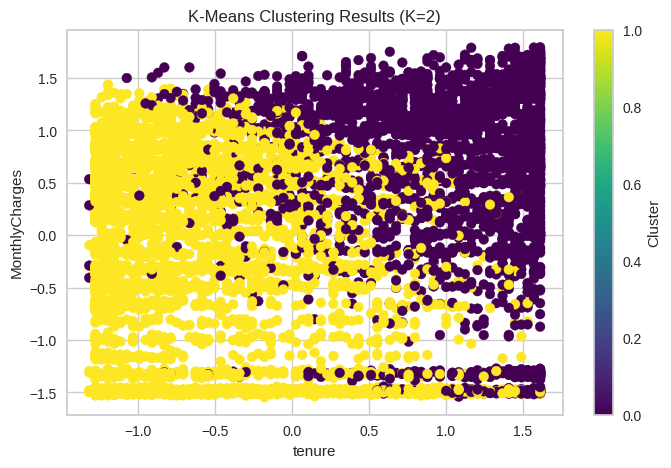

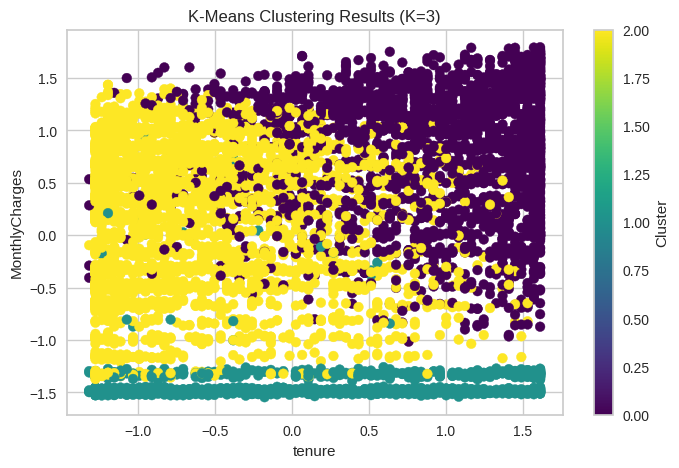

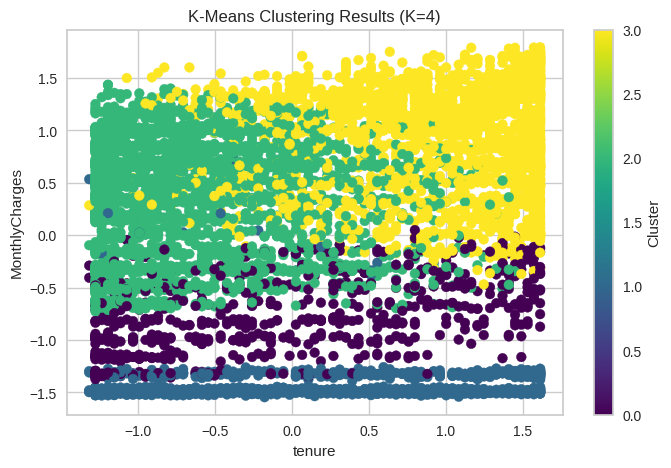

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = [2, 3, 4]

for k in k_values:

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    kmeans_result = kmeans.fit(scaled_features)

    scaled_data['Cluster'] = kmeans_result.labels_

    plt.figure(figsize=(8, 5))

    plt.scatter(
        scaled_data['tenure'],
        scaled_data['MonthlyCharges'],
        c=scaled_data['Cluster'],
        cmap='viridis'
    )

    plt.xlabel('tenure')
    plt.ylabel('MonthlyCharges')
    plt.title(f'K-Means Clustering Results (K={k})')
    plt.colorbar(label='Cluster')
    plt.show()

scaled_data.drop(columns=['Cluster'], inplace=True)

#### Cluster Visualization Description

K-Means clustering was applied using K=2, K=3, and K=4 to visualize the distribution of customers across different clusters.

The scatter plots display the standardized `tenure` attribute on the x-axis and the standardized `MonthlyCharges` attribute on the y-axis.

Each point represents a customer, and different colors indicate the cluster assigned by K-Means.

These visualizations help examine how customers are grouped according to their subscription duration and monthly charges.

Since K-Means was trained using all selected features, the two-dimensional plots provide only a partial representation of the clustering results.

The visualizations will be compared to examine the distribution and overlap of customer groups for each K value.


#### Cluster Visualization Results Discussion

The scatter plots illustrate the K-Means clustering results for K=2, K=3, and K=4 using the standardized `tenure` and `MonthlyCharges` attributes.

**K=2 (Two Clusters):**

The first cluster (purple) is mainly concentrated among customers with higher tenure values, while the second cluster (yellow) is more concentrated among customers with lower tenure values. However, some overlap exists between the two clusters, particularly in the middle of the plot.

K=2 achieved the highest Silhouette Score of **0.1571**, indicating the best average cluster cohesion and separation among the tested K values, although the separation remains relatively weak.

**K=3 (Three Clusters):**

When K increased to 3, an additional cluster appeared at the lower end of the MonthlyCharges axis. This cluster contains customers with very low monthly charges across different tenure values.

However, the other two clusters still show considerable overlap. The Silhouette Score decreased to **0.1381**, indicating that adding a third cluster did not improve the overall clustering quality according to this metric.

**K=4 (Four Clusters):**

With K=4, the customers were divided into four groups with different distributions.

One cluster is concentrated at very low monthly charges, while another mainly includes customers with low to moderate monthly charges.

The remaining clusters show differences in tenure and monthly charges, including groups with shorter tenure and higher monthly charges and groups with longer tenure and higher monthly charges.

K=4 achieved a Silhouette Score of **0.1553**, which is very close to the highest score obtained at K=2. The Elbow Method also suggested K=4 as a reasonable candidate.

**Overall Comparison:**

The visualizations show that increasing K produces more detailed customer groups, but it does not necessarily improve cluster separation.

K=2 achieved the highest Silhouette Score, while K=4 provided a more detailed segmentation of customers based on their tenure and monthly charges.

However, overlap remains visible in all three plots, which is consistent with the relatively low Silhouette Scores.

These findings suggest that both K=2 and K=4 are reasonable candidates. Further analysis of cluster characteristics helps determine which configuration provides more meaningful customer segmentation.


**Additional Cluster Visualization Using Relevant Attributes**

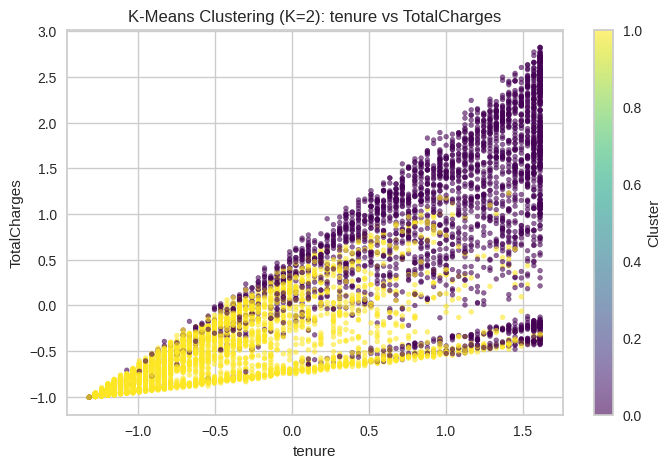

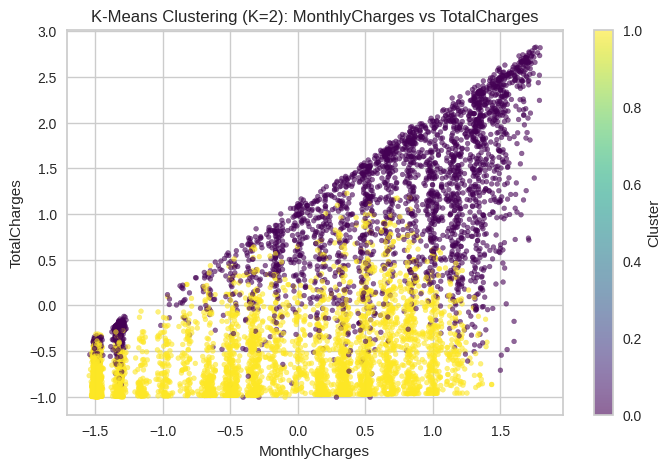

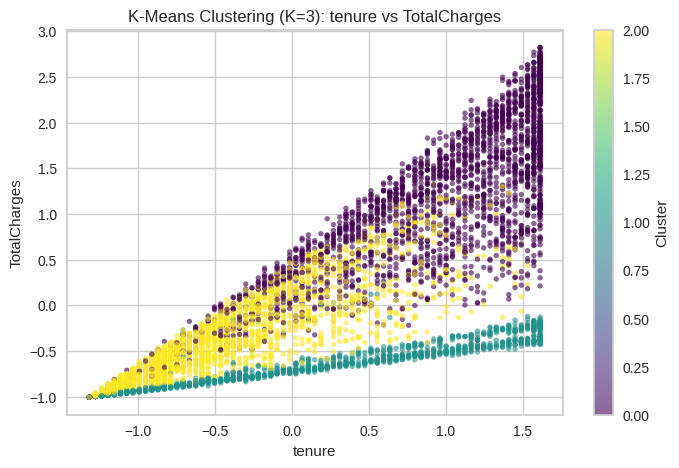

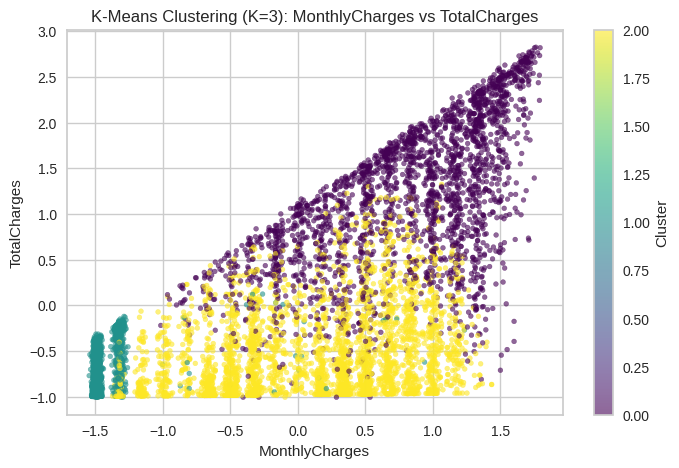

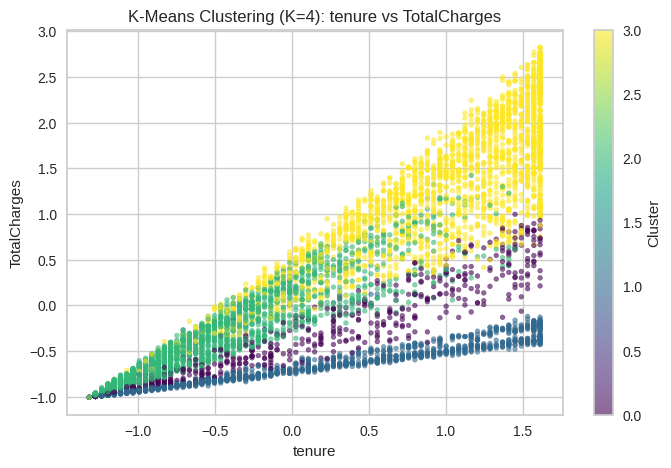

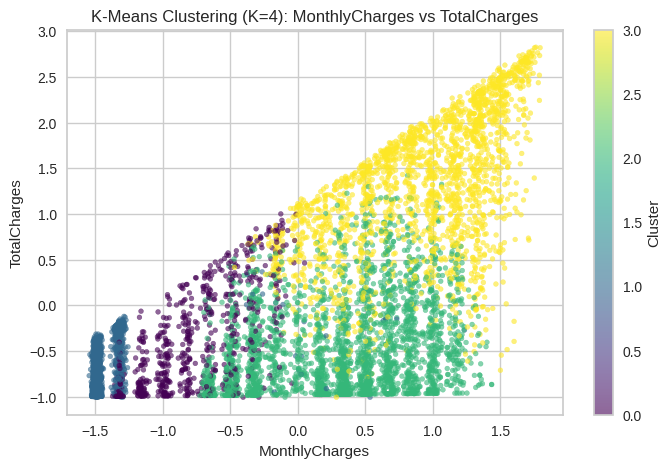

In [ ]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = [2, 3, 4]

column_pairs = [
    ('tenure', 'TotalCharges'),
    ('MonthlyCharges', 'TotalCharges')
]

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_features)

    for x_col, y_col in column_pairs:
        plt.figure(figsize=(8, 5))

        plt.scatter(
            scaled_data[x_col],
            scaled_data[y_col],
            c=labels,
            cmap='viridis',
            alpha=0.6,
            s=12
        )

        plt.xlabel(x_col)
        plt.ylabel(y_col)
        plt.title(f'K-Means Clustering (K={k}): {x_col} vs {y_col}')
        plt.colorbar(label='Cluster')
        plt.show()


**Additional Cluster Visualization Results Discussion**

The additional scatter plots illustrate the relationships between tenure, MonthlyCharges, and TotalCharges for K=2, K=3, and K=4.

K=2: The two clusters show differences in customer tenure and total charges. Cluster 0 generally contains customers with higher tenure and total charges, while Cluster 1 contains more customers with lower values. Some overlap exists between the clusters.

K=3: Three clusters are identified. Cluster 0 generally has higher total charges, Cluster 1 is characterized by low monthly and total charges, and Cluster 2 contains many customers with relatively low total charges across different monthly charge levels.

K=4: Four customer groups are identified with more detailed differences. Cluster 3 generally contains customers with higher total charges, Cluster 1 has very low monthly charges, and Cluster 2 includes many customers with low total charges. Cluster 0 contains customers with relatively lower monthly charges and varying total charges.

Overall, the visualizations show that increasing K provides more detailed customer segments. However, some overlap remains between clusters.

#### Silhouette Plots for Different K Values

Silhouette plots are used to visualize the quality of clusters generated by K-Means for K=2, K=3, and K=4.

Each plot shows the distribution of Silhouette Coefficients for customers within each cluster.

These plots help evaluate cluster cohesion, separation, and the presence of overlapping or poorly assigned data points.

The results will be compared to identify which K value provides better clustering performance.


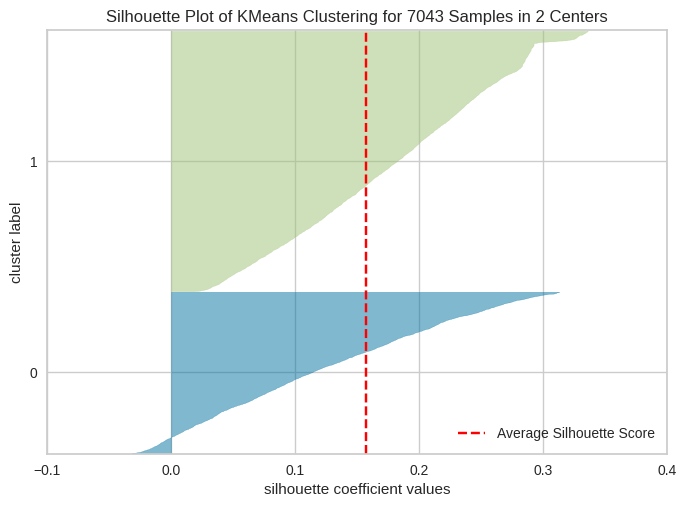

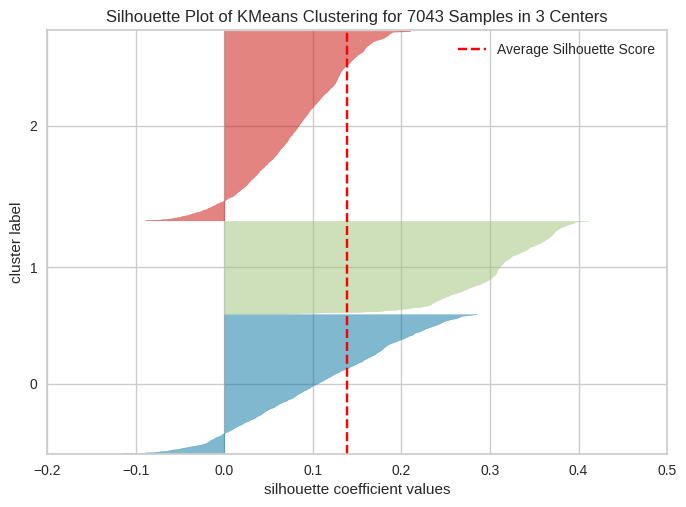

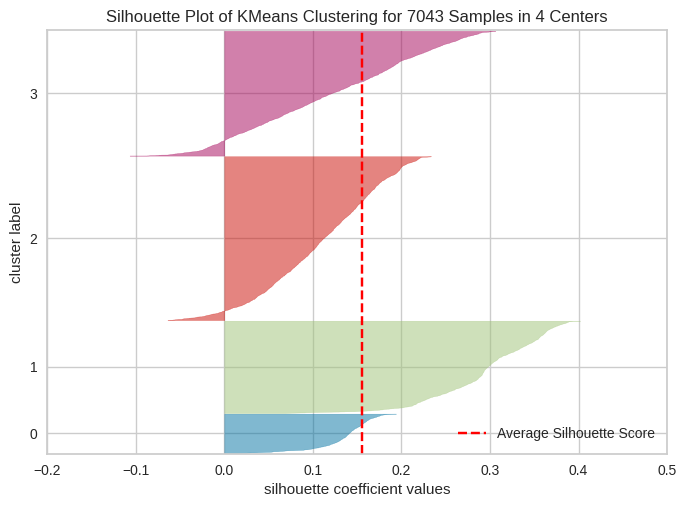

In [ ]:
from yellowbrick.cluster import SilhouetteVisualizer
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

k_values = [2, 3, 4]

for k in k_values:

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)

    visualizer = SilhouetteVisualizer(
        kmeans,
        colors='yellowbrick'
    )

    visualizer.fit(scaled_features)
    visualizer.show()

#### Silhouette Plots Description

Silhouette plots were generated for three different numbers of clusters: K=2, K=3, and K=4.

The `SilhouetteVisualizer` from the Yellowbrick library was used to visualize the distribution of Silhouette Coefficients for each cluster.

Each colored section represents a cluster, and its width indicates the Silhouette Coefficients of the customers assigned to that cluster.

The red dashed line represents the average Silhouette Score.

Customers with higher positive coefficients are generally well assigned to their clusters, while coefficients close to zero indicate overlapping clusters. Negative coefficients suggest that some customers may be closer to another cluster.

These visualizations help compare the quality of the clustering results and support the selection of the optimal K.


#### Silhouette Plots Results Discussion

The Silhouette Plots were generated for K=2, K=3, and K=4 to evaluate the clustering quality and examine the distribution of Silhouette Coefficients within each cluster.

**K=2:**

The plot shows two clusters with mostly positive Silhouette Coefficients. However, some negative values are present, indicating that certain customers may be closer to another cluster.

K=2 achieved the highest average Silhouette Score of **0.1571**, suggesting better overall cluster cohesion and separation compared to K=3 and K=4.

**K=3:**

The plot shows three clusters with different sizes and distributions. Some negative Silhouette Coefficients are observed, suggesting possible overlap between customer groups.

The average Silhouette Score was **0.1381**, which is lower than K=2 and K=4. This indicates that dividing customers into three groups did not improve the clustering quality according to this metric.

**K=4:**

The plot shows four clusters with varying sizes and Silhouette Coefficients. Some clusters contain relatively high positive values, while others include low or negative values.

K=4 achieved an average Silhouette Score of **0.1553**, which is very close to the score obtained with K=2.

**Overall Interpretation:**

The Silhouette Plots indicate that K=2 provides the highest average cluster cohesion and separation among the tested configurations, while K=4 achieves a comparable score and provides a more detailed customer segmentation.

All three configurations contain some negative Silhouette Coefficients, suggesting possible overlap between clusters.

Overall, K=2 performs slightly better according to Silhouette Score, while K=4 remains a reasonable alternative when more detailed customer segmentation is desired.


#### Determining the Optimal K Using Majority Rule

The optimal number of clusters is determined by comparing the results of different evaluation methods.

Three factors are considered:

1. **Silhouette Score:** Identifies the K value with the highest average cluster cohesion and separation.
2. **Elbow Method:** Identifies a suitable K value based on the reduction in WCSS.
3. **Cluster Visualization:** Examines the distribution and interpretability of the resulting customer groups.

The final K value is selected by considering the agreement between these evaluation results.


In [ ]:
print("K-Means Evaluation Results:")
display(comparison_table.round(4))

best_k_silhouette = [2, 3, 4][
    silhouette_results.index(max(silhouette_results))
]

print("Best K based on Silhouette Score:", best_k_silhouette)
print("Highest Silhouette Score:", round(max(silhouette_results), 4))

K-Means Evaluation Results:


,Evaluation Metric,K=2,K=3,K=4
0,Average Silhouette Width,0.1571,0.1381,0.1553
1,Total WCSS,112918.3725,101487.1241,94693.5311


Best K based on Silhouette Score: 2
Highest Silhouette Score: 0.1571


#### Optimal K Evaluation Discussion

The optimal number of clusters was evaluated using the Silhouette Score, Elbow Method, and cluster visualization.

**Silhouette Score:** K=2 achieved the highest Silhouette Score of 0.1571, followed closely by K=4 with 0.1553. The difference between the two configurations is only 0.0018, indicating similar average clustering quality.

**Elbow Method:** The WCSS curve showed a gradual reduction in improvement around K=4, suggesting that four clusters may provide a reasonable balance between cluster compactness and the number of clusters. However, the elbow point was not sharply defined.

**Cluster Visualization:** K=4 produced four customer groups with different distributions of tenure and monthly charges, providing more detailed segmentation than K=2. However, overlap was observed between several groups.

**Conclusion:**

The evaluation results suggest that both K=2 and K=4 are reasonable candidates.

K=2 is preferred based on the Silhouette Score, while K=4 is supported by the approximate elbow point and provides more detailed customer segmentation.

Since the evaluation methods do not clearly agree, cluster characteristics and interpretability are also considered before selecting the final optimal K.


#### Cluster Characteristics Analysis

To further evaluate the clustering results, the characteristics of customers in each cluster are analyzed for K=2 and K=4.

The analysis focuses on three attributes: `tenure`, `MonthlyCharges`, and `TotalCharges`.

These attributes help us understand the differences between customer groups in terms of subscription duration and service charges.

The number of customers and the average values of these attributes are calculated for each cluster.

This analysis supports the selection of the optimal K by examining whether the resulting clusters provide meaningful customer segmentation.


In [ ]:
from sklearn.cluster import KMeans

k_values = [2, 3, 4]

for k in k_values:

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_result = kmeans.fit(scaled_features)

    clustered_data = df.copy()
    clustered_data['Cluster'] = kmeans_result.labels_

    print("K =", k)

    print("Number of Customers in Each Cluster:")
    print(clustered_data['Cluster'].value_counts().sort_index())

    print("Average Customer Characteristics:")
    display(
        clustered_data.groupby('Cluster')[
            ['tenure', 'MonthlyCharges', 'TotalCharges']
        ].mean().round(4)
    )

K = 2
Number of Customers in Each Cluster:
Cluster
0    2696
1    4347
Name: count, dtype: int64
Average Customer Characteristics:


,tenure,MonthlyCharges,TotalCharges
Cluster,,,
0,0.7787,0.6269,0.5194
1,0.2455,0.3610,0.1032


K = 3
Number of Customers in Each Cluster:
Cluster
0    2324
1    1550
2    3169
Name: count, dtype: int64
Average Customer Characteristics:


,tenure,MonthlyCharges,TotalCharges
Cluster,,,
0,0.7697,0.7035,0.5689
1,0.4219,0.0348,0.0775
2,0.2284,0.4957,0.1283


K = 4
Number of Customers in Each Cluster:
Cluster
0     662
1    1547
2    2744
3    2090
Name: count, dtype: int64
Average Customer Characteristics:


,tenure,MonthlyCharges,TotalCharges
Cluster,,,
0,0.4240,0.2297,0.1613
1,0.4228,0.0349,0.0778
2,0.2220,0.5512,0.1374
3,0.7764,0.7373,0.5956


#### Cluster Characteristics Description

The customer characteristics were examined for K=2, K=3, and K=4 to evaluate the interpretability of the generated clusters.

For each K value, K-Means was applied to the standardized dataset, and customers were assigned to their corresponding clusters.

The number of customers in each cluster was calculated to examine the distribution of cluster sizes.

Additionally, the average values of tenure, monthly charges, and total charges were calculated for each cluster using the preprocessed dataset.

These results help identify differences between customer groups and determine whether using four clusters provides more meaningful customer segmentation compared to two clusters.

The findings will be considered alongside the Silhouette Score and Elbow Method when selecting the optimal K.


#### Cluster Characteristics Results Discussion

The characteristics of customers were analyzed for K=2, K=3, and K=4 by comparing cluster sizes and the average values of tenure, MonthlyCharges, and TotalCharges.

**K=2:**

Cluster 0 contains 2,696 customers and has higher average tenure (0.7787), MonthlyCharges (0.6269), and TotalCharges (0.5194). This cluster represents customers with relatively longer subscription durations and higher charges.

Cluster 1 contains 4,347 customers and has lower average tenure (0.2455), MonthlyCharges (0.3610), and TotalCharges (0.1032). This cluster represents customers with shorter subscription durations and lower charges.

These results show that K=2 provides a broad division of customers into two groups based on subscription duration and charges.

**K=3:**

Cluster 0 contains 2,324 customers and has higher average tenure (0.7697), MonthlyCharges (0.7035), and TotalCharges (0.5689). This cluster represents customers with longer subscription durations and higher charges.

Cluster 1 contains 1,550 customers and has moderate tenure (0.4219), very low MonthlyCharges (0.0348), and low TotalCharges (0.0775). This cluster represents customers with moderate subscription durations and very low charges.

Cluster 2 contains 3,169 customers and has shorter tenure (0.2284), moderate MonthlyCharges (0.4957), and relatively low TotalCharges (0.1283). This cluster represents customers with shorter subscription durations and moderate monthly charges.

These results show that K=3 provides a more detailed division of customers into three groups based on subscription duration and charges.


**K=4:**

Cluster 0 contains 662 customers with moderate tenure (0.4240) and relatively low MonthlyCharges (0.2297).

Cluster 1 contains 1,547 customers with moderate tenure (0.4228) and very low MonthlyCharges (0.0349).

Cluster 2 contains 2,744 customers with shorter tenure (0.2220) and moderate to high MonthlyCharges (0.5512).

Cluster 3 contains 2,090 customers with longer tenure (0.7764) and higher MonthlyCharges (0.7373).

**Overall Interpretation:**

K=2 provides a simpler division of customers into two main groups, while K=3 identifies three groups with different subscription durations and spending patterns. K=4 provides a more detailed division by identifying four groups with additional differences in customer characteristics.

These differences make K=4 potentially more useful for customer segmentation, as it provides additional information about customer characteristics.

Although the Churn attribute was excluded from the clustering process, the churn rates were analyzed separately after clustering to better understand the relationship between customer characteristics and churn behavior.

**Churn Rate Analysis for Each Cluster**

In [ ]:

from sklearn.cluster import KMeans

k_values = [2, 3, 4]

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(scaled_features)

    clustered_data = df.copy()
    clustered_data['Cluster'] = labels

    print(f"\nChurn Rate Analysis for K={k}")

    churn_analysis = clustered_data.groupby('Cluster').agg(
        Customers=('Churn', 'size'),
        Churn_Rate=('Churn', 'mean')
    )

    churn_analysis['Churn_Rate'] = (
        churn_analysis['Churn_Rate'] * 100
    ).round(2)

    display(churn_analysis)



Churn Rate Analysis for K=2


,Customers,Churn_Rate
Cluster,,
0,2696,13.76
1,4347,34.46



Churn Rate Analysis for K=3


,Customers,Churn_Rate
Cluster,,
0,2324,14.80
1,1550,7.42
2,3169,44.49



Churn Rate Analysis for K=4


,Customers,Churn_Rate
Cluster,,
0,662,25.68
1,1547,7.43
2,2744,45.95
3,2090,15.45


**Churn Rate Analysis Results Discussion**

The churn rates were analyzed for K=2, K=3, and K=4 to understand the relationship between customer clusters and customer churn.

**K=2:**

Cluster 0 has a churn rate of 13.76%, while Cluster 1 has a higher churn rate of 34.46%. This indicates that customers with shorter subscription durations and lower charges tend to have higher churn rates.

**K=3:**

Cluster 0 has a churn rate of 14.80%, Cluster 1 has the lowest churn rate of 7.42%, and Cluster 2 has the highest churn rate of 44.49%.

These results indicate that customers with shorter subscription durations and moderate monthly charges have a higher churn rate.

**K=4:**

Cluster 0 has a churn rate of 25.68%, Cluster 1 has the lowest churn rate of 7.43%, Cluster 2 has the highest churn rate of 45.95%, and Cluster 3 has a churn rate of 15.45%.

These results show that K=4 identifies customer groups with different churn rates and provides a more detailed understanding of customer behavior.

**Overall Interpretation:**

The analysis shows that customer clusters have different churn rates. Customers with shorter subscription durations and relatively higher monthly charges tend to have higher churn rates.

K=4 provides a more detailed customer segmentation, which may help identify customer groups that require greater attention to reduce churn.

The Churn attribute was not used to train the K-Means models. It was used only after clustering to analyze the churn rates within each cluster.

#### Final Optimal K Selection

The optimal number of clusters was selected by considering the Silhouette Score, Elbow Method, and the interpretability of customer groups.

**Silhouette Score:**

K=2 achieved the highest Silhouette Score of 0.1571, while K=4 achieved a very similar score of 0.1553. The difference between the two values is only 0.0018, indicating comparable average clustering quality.

**Elbow Method:**

The WCSS curve showed that the reduction in WCSS became more gradual around K=4. Although the elbow point was not sharply defined, K=4 was considered a reasonable candidate.

**Cluster Characteristics:**

K=2 divided customers into two broad groups based on subscription duration and service charges.

In comparison, K=4 identified four customer groups with more detailed differences in tenure, monthly charges, and total charges.

**Final Decision: K=4**

K=4 was selected as the preferred number of clusters because it provides more detailed and interpretable customer segmentation while maintaining a Silhouette Score close to K=2.

Although K=2 achieved the highest Silhouette Score, K=4 offered a reasonable balance between cluster quality and the level of detail in customer segmentation.

The evaluation methods did not establish a clear numerical majority. Therefore, K=4 was selected based on the combined evaluation results and cluster interpretability rather than a strict majority vote.

Overall, K=4 was considered the preferred configuration for exploring customer segments in the Telco Customer Churn dataset.


#[7] Findings and Discussion

This section interprets the results of section [6] in the context of the research problem. It compares the two attribute selection measures, examines what the final decision tree and the customer clusters reveal about churn, and compares our findings with the research paper by Ahmad et al. [1]. All values shown below are computed by the code cells in this section, using the same data, partitions, and random seeds as section [6].


### 7.1 Classification: Gini Index vs Information Gain (Entropy)

The table below repeats the classification experiment of section [6]. Each Decision Tree is trained with the same partitions and random seeds, so the test accuracies match sections 6.1–6.3 exactly. The table adds four measures that help to interpret the accuracies:

* the accuracy on the **training** set;
* the **recall of each class**, i.e., the share of churners and of non-churners that are classified correctly;
* the **majority-class baseline**, i.e., the accuracy obtained by always predicting "No churn";
* the **size** of each tree (depth and number of leaves).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

url = "https://raw.githubusercontent.com/LujainAldujain/Data_Mining_Project/refs/heads/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)

X = df.drop(columns=['Churn', 'customerID'])
y = df['Churn']

splits = {"90/10": 0.1, "80/20": 0.2, "70/30": 0.3}
criteria = {"gini": "Gini Index", "entropy": "Information Gain (Entropy)"}
rows = []

for criterion, criterion_name in criteria.items():
    for split_name, test_size in splits.items():
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=1)
        clf = DecisionTreeClassifier(criterion=criterion, random_state=42)
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)

        rows.append({
            "Criterion": criterion_name,
            "Split": split_name,
            "Test Accuracy (%)": accuracy_score(y_test, y_pred) * 100,
            "Training Accuracy (%)": clf.score(X_train, y_train) * 100,
            "Churn Recall (%)": cm[1, 1] / cm[1].sum() * 100,
            "No-Churn Recall (%)": cm[0, 0] / cm[0].sum() * 100,
            "Majority-Class Baseline (%)": (1 - y_test.mean()) * 100,
            "Tree Depth": clf.get_depth(),
            "Leaves": clf.get_n_leaves()
        })

classification_summary = pd.DataFrame(rows)
display(classification_summary.round(2))

average_accuracy = classification_summary.groupby("Criterion")["Test Accuracy (%)"].mean().round(2)
print("Average test accuracy across the three partitions:")
print(average_accuracy)

,Criterion,Split,Test Accuracy (%),Training Accuracy (%),Churn Recall (%),No-Churn Recall (%),Majority-Class Baseline (%),Tree Depth,Leaves
0,Gini Index,90/10,72.62,99.78,53.49,78.80,75.60,29,1245
1,Gini Index,80/20,72.75,99.80,50.29,80.11,75.30,25,1143
2,Gini Index,70/30,73.69,99.80,51.14,81.20,75.01,25,1003
3,Information Gain (Entropy),90/10,71.35,99.78,52.91,77.30,75.60,45,1202
4,Information Gain (Entropy),80/20,73.60,99.80,52.59,80.49,75.30,28,1115
5,Information Gain (Entropy),70/30,74.40,99.80,52.46,81.70,75.01,30,990


Average test accuracy across the three partitions:
Criterion
Gini Index                    73.02
Information Gain (Entropy)    73.11
Name: Test Accuracy (%), dtype: float64


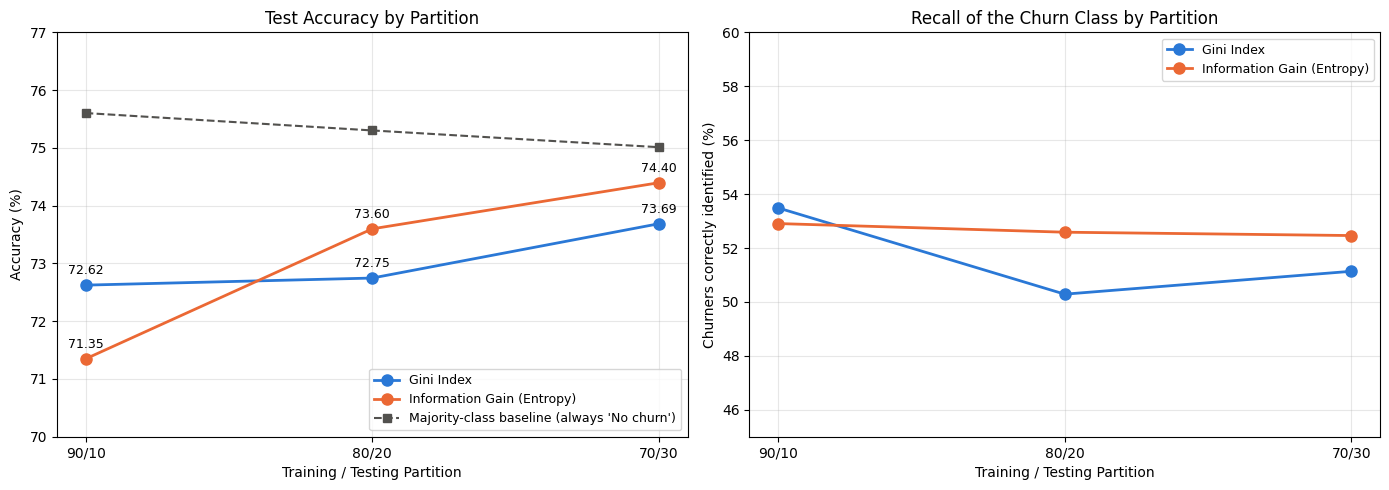

In [ ]:
split_order = list(splits)
colors = {"Gini Index": "#2a78d6", "Information Gain (Entropy)": "#eb6834"}

accuracy = classification_summary.pivot(index="Split", columns="Criterion", values="Test Accuracy (%)").loc[split_order]
churn_recall = classification_summary.pivot(index="Split", columns="Criterion", values="Churn Recall (%)").loc[split_order]
baseline = classification_summary.groupby("Split")["Majority-Class Baseline (%)"].first().loc[split_order]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for criterion_name, color in colors.items():
    axes[0].plot(split_order, accuracy[criterion_name], marker="o", markersize=8, linewidth=2, color=color, label=criterion_name)
    axes[1].plot(split_order, churn_recall[criterion_name], marker="o", markersize=8, linewidth=2, color=color, label=criterion_name)
    for i, value in enumerate(accuracy[criterion_name]):
        axes[0].annotate(f"{value:.2f}", (i, value), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)

axes[0].plot(split_order, baseline, linestyle="--", marker="s", color="#52514e", label="Majority-class baseline (always 'No churn')")
axes[0].set_title("Test Accuracy by Partition")
axes[0].set_xlabel("Training / Testing Partition")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(70, 77)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Recall of the Churn Class by Partition")
axes[1].set_xlabel("Training / Testing Partition")
axes[1].set_ylabel("Churners correctly identified (%)")
axes[1].set_ylim(45, 60)
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

#### Discussion of the Classification Results

**Best criterion for each partition:** The Gini Index achieved the higher accuracy on the 90/10 partition (72.62% vs 71.35%). Information Gain achieved the higher accuracy on the 80/20 partition (73.60% vs 72.75%) and on the 70/30 partition (74.40% vs 73.69%). These results are identical to those reported in section 6.3.

**Best model overall:** The best-performing model is the **Decision Tree using Information Gain (Entropy) with the 70/30 partition, with an accuracy of 74.40%**. Information Gain also has the slightly higher average accuracy across the three partitions (73.11% vs 73.02%), and it identifies a slightly larger share of churners on the 80/20 and 70/30 partitions (52.59% and 52.46%, compared with 50.29% and 51.14% for the Gini Index). However, the overall difference between the two measures is only 0.09 percentage points, so on this dataset the choice of attribute selection measure has very little practical effect.

**Why the two measures perform so similarly:** The Gini Index and Entropy are two measures of node impurity that are both lowest for pure nodes and highest for evenly mixed nodes [3]. They usually rank candidate splits in a very similar order. This is confirmed on the 70/30 partition, where the trees built with the two measures choose exactly the same first three splits (`Contract`, followed by `OnlineSecurity` and `MonthlyCharges`). The two trees differ only in their lower levels, and this is where the small differences in accuracy arise.

**Why the partitions behave differently:** The 90/10 partition gave the lowest accuracy for both measures, even though it uses the most training data. Its test set contains only 705 customers, so each prediction changes the accuracy by about 0.14 percentage points, and the result depends strongly on which customers happen to fall into this small test set. The 70/30 partition has the largest test set (2,113 customers) and therefore gives the most reliable estimate. Because each partition was evaluated on a single random split, differences of about one percentage point between the two measures should not be over-interpreted.

**What the additional measures reveal:**

* **Overfitting.** Every tree classifies 99.78–99.80% of its training data correctly but only 71–74% of its testing data. Both measures were used without any depth limit or pruning, so the trees grew very large (depth 25–45, with 990–1,245 leaves). In effect, they memorize individual training customers instead of learning general rules.
* **Accuracy is misleading.** Because about 75% of the test customers did not churn, a model that always predicts "No churn" would reach 75.01–75.60% accuracy. This is slightly higher than every tree. The trees are still more useful than this baseline, which identifies no churners at all, but they correctly identify only about half of the churners (50.29–53.49%), while recognizing 77–82% of the non-churners. For a company whose goal is to retain customers, the churners that are missed matter more than the overall accuracy suggests.

### 7.2 What the Final Decision Tree Reveals

The best-performing model (Information Gain with the 70/30 partition) is retrained below to examine how it classifies customers. The top levels of the tree and the feature importances show which attributes drive the predictions. The churn rates computed from the raw dataset show what each important split means in practice.

Test accuracy of the final tree: 74.4 %

Top three levels of the final tree:
|--- Contract <= 0.50
|   |--- OnlineSecurity <= 0.50
|   |   |--- tenure <= 0.08
|   |   |   |--- truncated branch of depth 20
|   |   |--- tenure >  0.08
|   |   |   |--- truncated branch of depth 28
|   |--- OnlineSecurity >  0.50
|   |   |--- OnlineBackup <= 0.50
|   |   |   |--- truncated branch of depth 15
|   |   |--- OnlineBackup >  0.50
|   |   |   |--- truncated branch of depth 25
|--- Contract >  0.50
|   |--- MonthlyCharges <= 0.75
|   |   |--- Contract <= 1.50
|   |   |   |--- truncated branch of depth 19
|   |   |--- Contract >  1.50
|   |   |   |--- truncated branch of depth 12
|   |--- MonthlyCharges >  0.75
|   |   |--- tenure <= 0.98
|   |   |   |--- truncated branch of depth 18
|   |   |--- tenure >  0.98
|   |   |   |--- truncated branch of depth 7



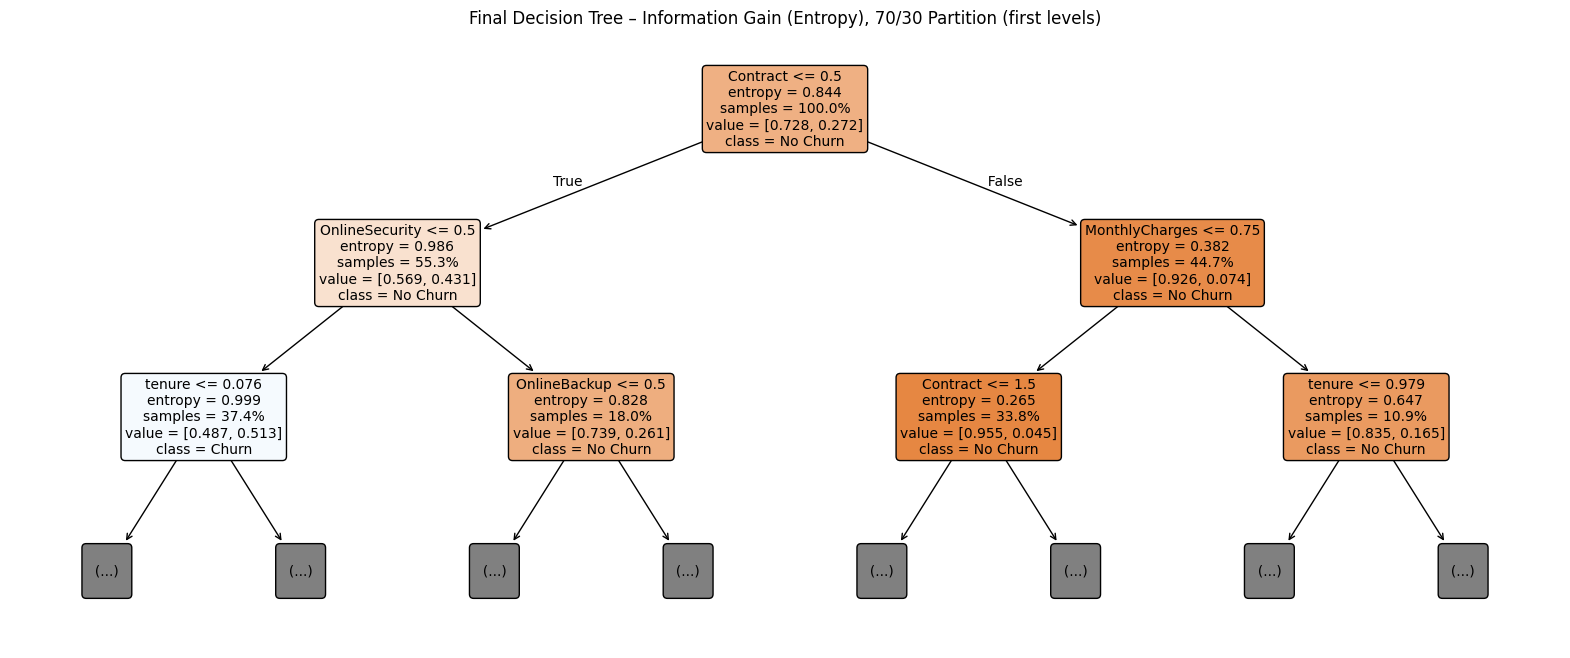

In [ ]:
from sklearn.tree import plot_tree, export_text

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)
final_tree = DecisionTreeClassifier(criterion="entropy", random_state=42)
final_tree.fit(X_train, y_train)

print("Test accuracy of the final tree:", round(accuracy_score(y_test, final_tree.predict(X_test)) * 100, 2), "%")
print("\nTop three levels of the final tree:")
print(export_text(final_tree, feature_names=list(X.columns), max_depth=2))

plt.figure(figsize=(20, 8))
plot_tree(final_tree, feature_names=list(X.columns), class_names=["No Churn", "Churn"],
          filled=True, rounded=True, fontsize=10, max_depth=2, impurity=True, proportion=True)
plt.title("Final Decision Tree – Information Gain (Entropy), 70/30 Partition (first levels)")
plt.show()

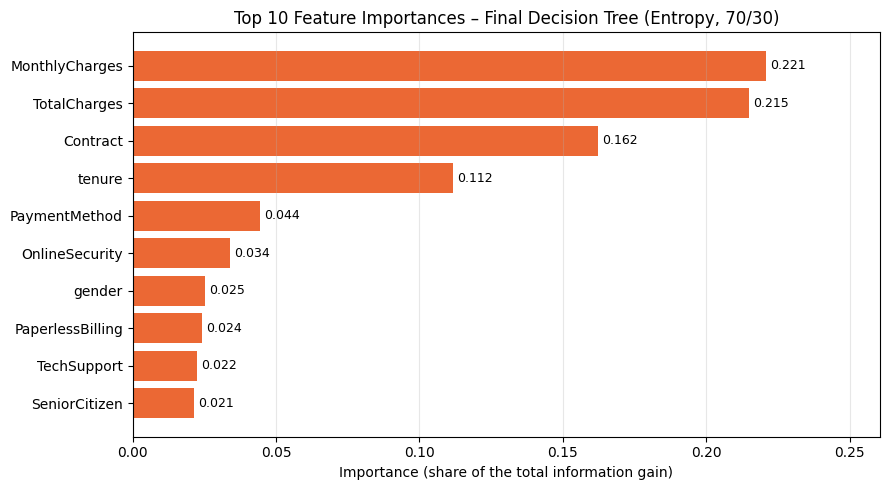

Share of the total importance held by the top four attributes: 70.97 %


In [ ]:
feature_importance = pd.Series(final_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
top_features = feature_importance.head(10).sort_values()

plt.figure(figsize=(9, 5))
bars = plt.barh(top_features.index, top_features.values, color="#eb6834")
plt.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
plt.title("Top 10 Feature Importances – Final Decision Tree (Entropy, 70/30)")
plt.xlabel("Importance (share of the total information gain)")
plt.xlim(0, top_features.max() * 1.18)
plt.grid(False)
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Share of the total importance held by the top four attributes:",
      round(feature_importance.head(4).sum() * 100, 2), "%")

In [ ]:
raw_url = "https://raw.githubusercontent.com/LujainAldujain/Data_Mining_Project/refs/heads/main/Dataset/Raw_dataset.csv"
raw_df = pd.read_csv(raw_url)
raw_df['Churned'] = (raw_df['Churn'] == 'Yes')

print("Churn rate (%) by contract type (first split of the tree):")
print((raw_df.groupby('Contract')['Churned'].mean() * 100).round(2))

month_to_month = raw_df[raw_df['Contract'] == 'Month-to-month']
print("\nMonth-to-month customers: churn rate (%) by OnlineSecurity (second split, left branch):")
print(month_to_month.groupby('OnlineSecurity')['Churned'].agg(Customers='size', Churn_Rate='mean')
      .assign(Churn_Rate=lambda t: (t['Churn_Rate'] * 100).round(2)))

# MonthlyCharges was Min-Max normalized in Phase 2, so the split threshold is converted back to dollars
threshold = final_tree.tree_.threshold[final_tree.tree_.children_right[0]]
threshold_dollars = threshold * (raw_df['MonthlyCharges'].max() - raw_df['MonthlyCharges'].min()) + raw_df['MonthlyCharges'].min()
long_contract = raw_df[raw_df['Contract'] != 'Month-to-month']
print(f"\nOne- and two-year contracts: churn rate (%) by MonthlyCharges above ${threshold_dollars:.2f} (second split, right branch):")
print(long_contract.groupby(long_contract['MonthlyCharges'] > threshold_dollars)['Churned'].agg(Customers='size', Churn_Rate='mean')
      .assign(Churn_Rate=lambda t: (t['Churn_Rate'] * 100).round(2)))

print("\nChurn rate (%) by payment method:")
print((raw_df.groupby('PaymentMethod')['Churned'].mean() * 100).round(2))

Churn rate (%) by contract type (first split of the tree):
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churned, dtype: float64

Month-to-month customers: churn rate (%) by OnlineSecurity (second split, left branch):
                     Customers  Churn_Rate
OnlineSecurity                            
No                        2631       51.05
No internet service        524       18.89
Yes                        720       29.58

One- and two-year contracts: churn rate (%) by MonthlyCharges above $93.67 (second split, right branch):
                Customers  Churn_Rate
MonthlyCharges                       
False                2390        3.97
True                  778       15.30

Churn rate (%) by payment method:
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churned, dtype: float64


#### Interpretation of the Final Decision Tree

**Contract type is the most informative attribute.** The tree uses `Contract` for its very first split (`Contract <= 0.5`, i.e., month-to-month contracts). The raw data shows why: 42.71% of month-to-month customers churned, compared with only 11.27% of customers on one-year contracts and 2.83% on two-year contracts. A customer without a long-term commitment can leave at any time, and this is the strongest single signal of churn in the dataset.

**The next splits identify the riskiest customers in each branch:**

* **Month-to-month branch (`OnlineSecurity`).** Among month-to-month customers, the tree next separates those without the online security service. These 2,631 customers churned at a rate of 51.05%, compared with 29.58% for month-to-month customers who do have online security. Customers who do not use additional support services appear to be less attached to the company.
* **One- and two-year branch (`MonthlyCharges`).** Among customers on longer contracts, the tree separates those who pay more than about $93.67 per month. These 778 customers churned at a rate of 15.30%, compared with 3.97% for the other long-contract customers. Even committed customers become more likely to leave when their bill is high.

**Feature importance:** Four attributes, `MonthlyCharges`, `TotalCharges`, `Contract` and `tenure`, together account for 71.0% of the information gain used by the tree. Contract length, how long a customer has stayed, and how much they pay are therefore the key drivers of churn in this dataset. `PaymentMethod` follows; customers paying by electronic check churned at 45.29%, compared with 15.24–19.11% for the other payment methods. Demographic attributes such as `gender` play only a minor role.

**Answer to the classification problem:** The decision tree can predict churn with an accuracy of 74.40%. It cannot yet be used as a reliable early-warning system, because it detects only about half of the churners. Its main value lies in the knowledge it extracts: customers on **month-to-month contracts, with short tenure, without online security, with high monthly charges, and paying by electronic check** form the group that a retention campaign should target first.

### 7.3 Clustering: Meaning of the Customer Segments

Section 6.4 selected **K = 4** as the optimal number of clusters, using the selected based on the combined evaluation results and cluster interoretability. To interpret the clusters in business terms, the cluster labels are attached to the **raw** dataset, so that the characteristics of each cluster can be expressed in months and dollars instead of normalized values. `Churn` was not used to form the clusters; it is used here only to describe them. The K = 2 solution is included for comparison.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

features = df.drop(columns=['Churn', 'customerID'])
scaled_features = StandardScaler().fit_transform(features)

def cluster_profile(labels):
    data = raw_df.copy()
    data['Cluster'] = labels
    data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce').fillna(0)
    groups = data.groupby('Cluster')
    profile = pd.DataFrame({
        'Customers': groups.size(),
        'Churn Rate (%)': groups['Churned'].mean() * 100,
        'Share of All Churners (%)': groups['Churned'].sum() / data['Churned'].sum() * 100,
        'Avg Tenure (months)': groups['tenure'].mean(),
        'Avg Monthly Charges ($)': groups['MonthlyCharges'].mean(),
        'Avg Total Charges ($)': groups['TotalCharges'].mean(),
        'Month-to-month (%)': groups['Contract'].apply(lambda s: (s == 'Month-to-month').mean() * 100),
        'Two-year Contract (%)': groups['Contract'].apply(lambda s: (s == 'Two year').mean() * 100),
        'Fiber Optic (%)': groups['InternetService'].apply(lambda s: (s == 'Fiber optic').mean() * 100),
        'DSL (%)': groups['InternetService'].apply(lambda s: (s == 'DSL').mean() * 100),
        'No Internet (%)': groups['InternetService'].apply(lambda s: (s == 'No').mean() * 100),
        'No Phone Service (%)': groups['PhoneService'].apply(lambda s: (s == 'No').mean() * 100),
        'Electronic Check (%)': groups['PaymentMethod'].apply(lambda s: (s == 'Electronic check').mean() * 100),
    })
    return data, profile.round(1)

cluster_labels = {}
for k in [2, 4]:
    cluster_labels[k] = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(scaled_features)
    clustered_raw, profile = cluster_profile(cluster_labels[k])
    print(f"Cluster profiles in original units for K={k}:")
    display(profile.T)

clustered_raw, profile_k4 = cluster_profile(cluster_labels[4])

Cluster profiles in original units for K=2:


Cluster,0,1
Customers,2696.0,4347.0
Churn Rate (%),13.8,34.5
Share of All Churners (%),19.9,80.1
Avg Tenure (months),56.1,17.7
Avg Monthly Charges ($),81.3,54.5
Avg Total Charges ($),4510.9,896.0
Month-to-month (%),21.6,75.8
Two-year Contract (%),48.0,9.2
Fiber Optic (%),52.4,38.7
DSL (%),36.0,33.4


Cluster profiles in original units for K=4:


Cluster,0,1,2,3
Customers,662.0,1547.0,2744.0,2090.0
Churn Rate (%),25.7,7.4,46.0,15.5
Share of All Churners (%),9.1,6.2,67.5,17.3
Avg Tenure (months),30.5,30.4,16.0,55.9
Avg Monthly Charges ($),41.3,21.8,73.6,92.3
Avg Total Charges ($),1400.5,675.6,1192.9,5172.6
Month-to-month (%),56.8,34.1,90.5,23.4
Two-year Contract (%),21.5,41.9,0.7,42.4
Fiber Optic (%),0.0,0.3,64.3,63.5
DSL (%),100.0,1.1,35.7,36.5


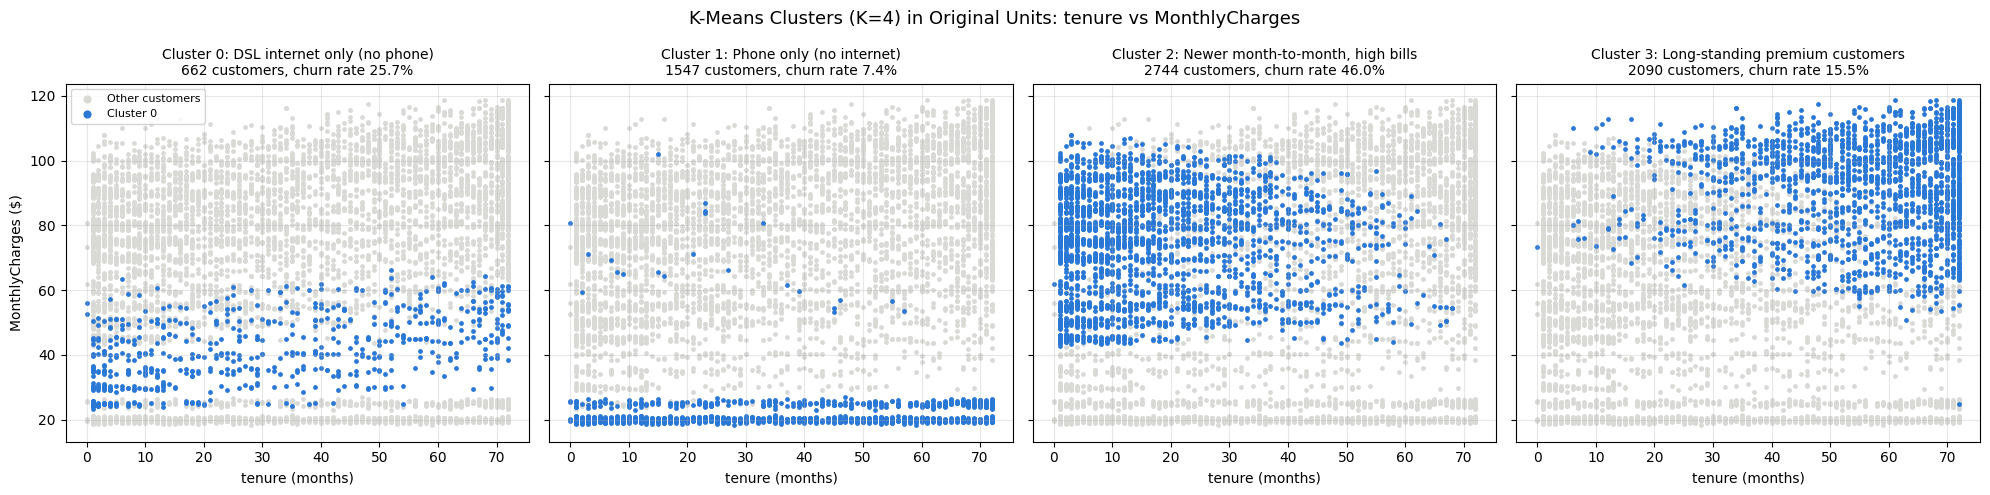

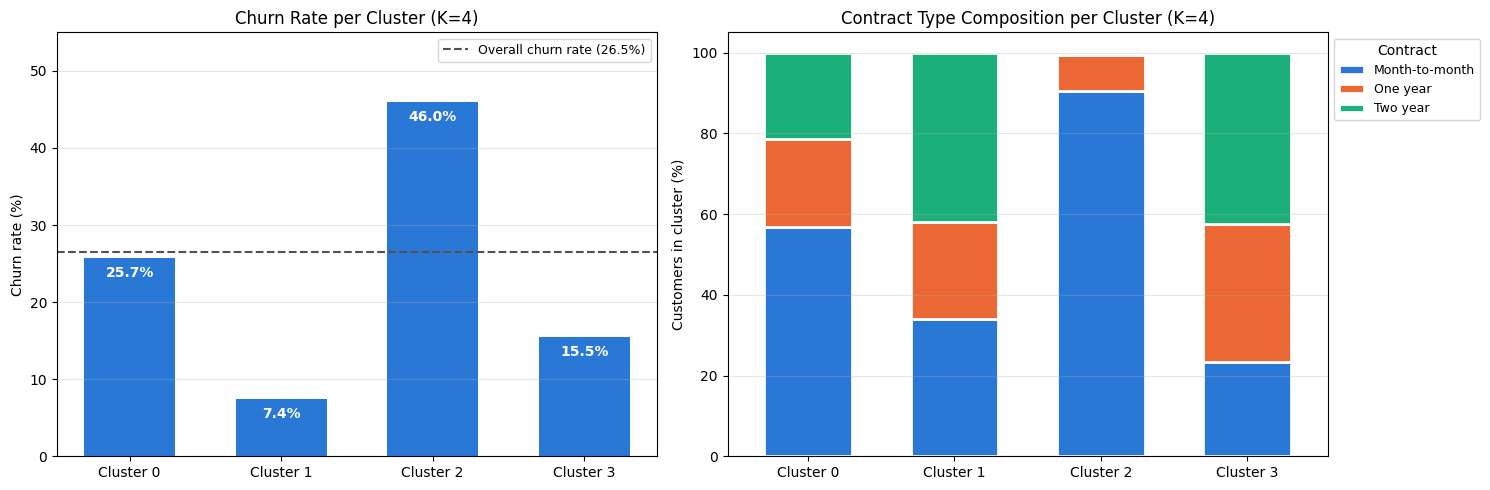

In [ ]:
segment_names = {
    0: "Cluster 0: DSL internet only (no phone)",
    1: "Cluster 1: Phone only (no internet)",
    2: "Cluster 2: Newer month-to-month, high bills",
    3: "Cluster 3: Long-standing premium customers",
}
overall_churn = raw_df['Churned'].mean() * 100

# (a) Each cluster highlighted against all customers, using the original tenure and MonthlyCharges values
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)
for cluster, ax in enumerate(axes):
    members = clustered_raw['Cluster'] == cluster
    ax.scatter(clustered_raw.loc[~members, 'tenure'], clustered_raw.loc[~members, 'MonthlyCharges'], s=6, color="#d9d9d6", label="Other customers")
    ax.scatter(clustered_raw.loc[members, 'tenure'], clustered_raw.loc[members, 'MonthlyCharges'], s=6, color="#2a78d6", label=f"Cluster {cluster}")
    ax.set_title(f"{segment_names[cluster]}\n{members.sum()} customers, churn rate {profile_k4.loc[cluster, 'Churn Rate (%)']}%", fontsize=10)
    ax.set_xlabel("tenure (months)")
    ax.grid(True, alpha=0.3)
axes[0].set_ylabel("MonthlyCharges ($)")
axes[0].legend(loc="upper left", fontsize=8, markerscale=2)
plt.suptitle("K-Means Clusters (K=4) in Original Units: tenure vs MonthlyCharges", fontsize=13)
plt.tight_layout()
plt.show()

# (b) Churn rate per cluster and (c) contract mix per cluster
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

bars = axes[0].bar([f"Cluster {c}" for c in profile_k4.index], profile_k4['Churn Rate (%)'], color="#2a78d6", width=0.6)
axes[0].bar_label(bars, fmt="%.1f%%", label_type="edge", padding=-16, color="white", fontsize=10, fontweight="bold")
axes[0].axhline(overall_churn, color="#52514e", linestyle="--", label=f"Overall churn rate ({overall_churn:.1f}%)")
axes[0].set_title("Churn Rate per Cluster (K=4)")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 55)
axes[0].legend(fontsize=9)
axes[0].grid(False)
axes[0].grid(True, axis="y", alpha=0.3)

contract_mix = pd.crosstab(clustered_raw['Cluster'], clustered_raw['Contract'], normalize='index') * 100
contract_mix = contract_mix[['Month-to-month', 'One year', 'Two year']]
contract_colors = ["#2a78d6", "#eb6834", "#1baf7a"]
contract_mix.index = [f"Cluster {c}" for c in contract_mix.index]
contract_mix.plot(kind='bar', stacked=True, ax=axes[1], color=contract_colors, rot=0, width=0.6, edgecolor="white", linewidth=2)
axes[1].set_title("Contract Type Composition per Cluster (K=4)")
axes[1].set_ylabel("Customers in cluster (%)")
axes[1].set_xlabel("")
axes[1].legend(title="Contract", fontsize=9, loc="upper left", bbox_to_anchor=(1.0, 1.0))
axes[1].grid(False)
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Interpretation of the Customer Segments

With K = 4, K-Means divides the customers into four clearly different segments:

| Cluster | Segment | Customers | Churn rate | Key characteristics |
|---|---|---|---|---|
| 2 | **Newer month-to-month customers with high bills** | 2,744 | **46.0%** | Average tenure of 16.0 months, $73.6 per month; 90.5% on month-to-month contracts; 64.3% use fiber optic; 51.6% pay by electronic check |
| 0 | **DSL internet-only customers** | 662 | 25.7% | All use DSL and none have phone service; average tenure of 30.5 months, $41.3 per month |
| 3 | **Long-standing premium customers** | 2,090 | 15.5% | Average tenure of 55.9 months, the highest bills at $92.3 per month; 42.4% on two-year contracts |
| 1 | **Phone-only customers** | 1,547 | 7.4% | 98.6% without internet service and the lowest bills at $21.8 per month; 41.9% on two-year contracts |

**Patterns and relationships discovered:**

* **Churn is concentrated in one segment.** Cluster 2 contains 39% of the customers but **67.5% of all churners**, and its churn rate (46.0%) is about 1.7 times the overall rate of 26.5%. Without using the class label, the clustering has therefore isolated the customer profile most at risk of churning.
* **High bills alone do not explain churn.** Clusters 2 and 3 both pay high monthly charges, and both consist mainly of fiber optic customers. Yet Cluster 3 churns at only 15.5%. The difference between them is commitment: Cluster 2 customers are recent and almost all on month-to-month contracts, while Cluster 3 customers have stayed for about 4.7 years on average, and most of them have one- or two-year contracts. This agrees with the decision tree, which also splits first on `Contract`.
* **Basic phone-only customers are the most loyal.** Cluster 1 pays the least and churns the least (7.4%). Customers with simple, low-cost plans and long contracts have little reason to switch providers.

**Significance of the optimal K:** K = 2 achieved the highest Silhouette score (0.1571), but its two clusters mainly separate customers by tenure: one cluster averages 56.1 months and the other 17.7 months. Its high-churn cluster (4,347 customers, 34.5% churn) mixes two very different groups. It contains the at-risk month-to-month customers, but 27.9% of its members have no internet service, and these phone-only customers rarely churn. K = 4 achieves almost the same Silhouette score (0.1553) and separates these groups. It isolates the phone-only and internet-only customers, and it splits the high-paying customers into a high-risk and a low-risk segment. The choice of K = 4 is therefore what turns the clustering into actionable information: it identifies **which** customers a retention campaign should target (Cluster 2), and which customers are already stable (Clusters 1 and 3).

**Quality of the clusters:** All Silhouette scores are low (at most 0.1571), so the clusters overlap considerably. A Silhouette value close to 0 means that an object lies close to the boundary between two clusters [4], and the scatter plots in section 6.4 confirm this overlap. Part of the separation is driven by discrete service attributes such as `PhoneService` and `InternetService`, which produce clearly separated groups (Clusters 0 and 1). The remaining customers lie along a continuous range of tenure and charges, which K-Means divides into Clusters 2 and 3 without a clear gap between them. The segments should therefore be read as useful profiles of typical customers rather than as sharply separated natural groups.

### 7.4 Classification and Clustering Together

| Aspect | Classification (Decision Tree) | Clustering (K-Means) |
|---|---|---|
| Learning type | Supervised: uses the `Churn` label | Unsupervised: `Churn` is not used to form the clusters |
| Evaluation metrics | Accuracy, confusion matrix | Silhouette coefficient, total within-cluster sum of squares (Elbow) |
| Best configuration | Information Gain (Entropy), 70/30 partition: **74.40% accuracy** | **K = 4** (majority rule): Silhouette 0.1553, WCSS 94,693.53 |
| Main result | Predicts churn for individual customers; detects about half of the churners | Divides customers into four segments with churn rates from 7.4% to 46.0% |
| Most important attributes | `Contract`, `tenure`, `MonthlyCharges`, `TotalCharges`, `OnlineSecurity` | Contract mix, tenure, monthly charges, and the type of internet and phone service |
| Practical use | Flag individual customers who are likely to churn | Design different retention strategies for each customer segment |

The two techniques were applied independently, yet they lead to the same conclusion. Both identify **short-tenure customers on month-to-month contracts with relatively high monthly charges** as the group most likely to churn:

* the decision tree finds this group through its first splits (`Contract`, `OnlineSecurity`, `tenure`);
* the clustering finds it as Cluster 2, which contains two thirds of all churners.

This agreement strengthens confidence that the pattern is a real characteristic of the data and not an artifact of one particular algorithm.

### 7.5 Comparison with the Research Paper

Our results are compared with the study by Ahmad et al. [1], which built a churn prediction model for the telecom operator SyriaTel and compared four tree-based algorithms: Decision Tree, Random Forest, Gradient Boosted Machine Tree (GBM), and XGBoost.

| Aspect | Ahmad et al. [1] | This project |
|---|---|---|
| Data | SyriaTel customer data covering 9 months (about 70 TB, about ten million customers); labeled sample of 5 million customers | Telco Customer Churn dataset [2]: 7,043 customers |
| Features | Over 2,000 engineered features (usage statistics from call records, complaints, devices, and social network analysis) | 19 attributes describing demographics, services, contract, and charges |
| Churn rate | About 5% (300,000 of 5 million) | 26.5% (1,869 of 7,043) |
| Class imbalance | Oversampling, undersampling, and no rebalancing were compared | No rebalancing |
| Partitioning | 70% training / 30% testing, with 10-fold cross-validation for tuning | 90/10, 80/20, and 70/30, one random split each |
| Decision Tree settings | Tuned: depth 20, 398 nodes | Default (unpruned): depth 25–45, 990–1,245 leaves |
| Evaluation metric | AUC | Accuracy and confusion matrix |
| Decision Tree result | AUC 83% with undersampling and 72.2% without rebalancing | Accuracy 71.35–74.40%; churn recall 50.29–53.49% |
| Best model | XGBoost (AUC 93.3%) | Decision Tree with Information Gain, 70/30 (accuracy 74.40%) |
| Clustering | Not performed | K-Means, optimal K = 4 |

**Similarities:**
* Both studies use tree-based classifiers, and both find that a single Decision Tree provides only moderate performance. In [1], the Decision Tree ranked last of the four algorithms.
* The 70/30 partition used by Ahmad et al. [1] is also the partition that gave the best and most reliable results in our experiments.
* Both studies remove unique identifiers before training: [1] removed attributes such as contract ID and MSISDN, and we removed `customerID`.
* Both studies face a minority churn class. Ahmad et al. [1] found that their Decision Tree performed best with undersampling (AUC 83% vs 72.2% without rebalancing). This agrees with our observation that the unbalanced trees miss about half of the churners.

**Differences and their likely causes:**
* **Evaluation metric.** [1] reports AUC, which measures how well a model ranks churners above non-churners across all decision thresholds. We report accuracy at a single threshold. The two measures are not directly comparable, so our 74.40% accuracy cannot be compared numerically with their AUC of 83% or 93.3%.
* **Data and features.** The SyriaTel model was trained on behavioral data: call and SMS activity, internet usage, complaints, and social network features. Its most important predictors were usage-based, such as the similarity of a customer's calling network to the competitor's customers, the number of days since the last outgoing transaction, and the total balance. Our dataset contains no usage data, so our most important attributes are contractual and financial (`Contract`, `tenure`, `MonthlyCharges`). The much larger and richer feature set is the main reason why the models in [1] achieve higher performance.
* **Methodology.** [1] tuned the tree depth and number of nodes with 10-fold cross-validation, rebalanced the training data, and used ensemble methods (Random Forest, GBM, XGBoost). Our trees use the default settings without pruning, rebalancing, or cross-validation, which explains the strong overfitting we observed.
* **Clustering.** [1] does not perform clustering. Our customer segmentation therefore extends the paper's approach: in addition to predicting which customers will churn, it describes which types of customers churn.

**Conclusion of the comparison:** Our findings **partially support** the findings of Ahmad et al. [1]:
* They agree that a single Decision Tree is a moderate churn predictor that suffers from class imbalance, and that a 70/30 partition is suitable.
* They differ in the attributes that drive churn and in the level of performance. These differences are explained by the very different data, features, metrics, and degree of model tuning, rather than by contradictory conclusions.

### 7.6 Limitations, Unexpected Observations, and Possible Improvements

**Unexpected observations:**
* The largest training set (90/10 partition) produced the lowest accuracy for both measures. This is explained by its small test set of 705 customers, not by worse learning.
* None of the decision trees exceeds the 75.0–75.6% accuracy of always predicting "No churn", even though the trees do find real churn patterns.
* K = 3 had a lower Silhouette score (0.1381) than both K = 2 and K = 4. Adding a third cluster did not improve the cluster quality, while adding a fourth cluster did.

**Limitations:**
* **No pruning or tuning.** The decision trees are fully grown (99.8% training accuracy, depth up to 45), so they overfit the training data.
* **Class imbalance and the choice of metric.** With 26.5% churners, accuracy hides the fact that only about half of the churners are detected. Precision, recall, F1-score, and AUC (the metric used in [1]) were not part of the required comparison.
* **A single split per partition.** Each partition was evaluated on one random split (`random_state=1`). Differences of about one percentage point between the Gini Index and Information Gain may therefore depend on the particular split.
* **Label encoding of nominal attributes.** Attributes such as `PaymentMethod` (0–3) and `InternetService` (0–2) were label-encoded in Phase 2. This gives their categories an artificial order and artificial distances, which affects the distance calculations of K-Means.
* **Weakly separated clusters.** The Silhouette scores of at most 0.157 indicate overlapping clusters. The segments are useful profiles, but they are not sharply separated natural groups.
* **Limited features.** The dataset contains no usage or behavioral data, which were the strongest predictors in [1].

**Possible improvements:**
* Limit the tree size (for example with `max_depth`, `min_samples_leaf`, or cost-complexity pruning [3]) to reduce overfitting.
* Handle the class imbalance with `class_weight="balanced"` or undersampling, which improved the Decision Tree in [1]. Report churn recall, F1-score, and AUC alongside accuracy.
* Use k-fold cross-validation instead of a single random split to obtain more stable estimates.
* Use one-hot encoding for nominal attributes before clustering, so that K-Means does not treat their categories as ordered.
* Evaluate ensemble methods such as Random Forest or gradient boosting, which outperformed the single Decision Tree in [1].

### 7.7 Conclusion

This project applied Decision Tree classification and K-Means clustering to the Telco Customer Churn dataset to answer two questions.

1. **Can churn be predicted?** The best classification model is the **Decision Tree with Information Gain (Entropy) trained on the 70/30 partition, with an accuracy of 74.40%**. The Gini Index performs almost identically (average accuracy of 73.02% vs 73.11%). The trees detect only about half of the churners and do not outperform a simple majority-class baseline. Without pruning and class balancing, they are therefore better suited to explaining churn than to predicting it reliably.
2. **Which customer groups exist?** K-Means with the optimal **K = 4** reveals four customer segments: newer month-to-month customers with high bills (46.0% churn), DSL internet-only customers (25.7%), long-standing premium customers (15.5%), and phone-only customers (7.4%).

Both techniques point to the same practical solution. Retention efforts should focus on **customers in their first months on month-to-month contracts with high monthly charges**, especially those without online security and those paying by electronic check. Offering these customers incentives to move to one- or two-year contracts is the most promising strategy, because longer contracts are associated with churn rates of only 2.8–11.3%.

#[8] References


[1] A. K. Ahmad, A. Jafar, and K. Aljoumaa, "Customer churn prediction in telecom using machine learning in big data platform," *Journal of Big Data*, vol. 6, no. 1, Art. no. 28, Mar. 2019, doi: 10.1186/s40537-019-0191-6.

[2] BlastChar, "Telco Customer Churn," Kaggle. Accessed: Nov. 7, 2026. [Online]. Available: https://www.kaggle.com/datasets/blastchar/telco-customer-churn

[3] J. Han, J. Pei, and H. Tong, *Data Mining: Concepts and Techniques*, 4th ed. Cambridge, MA, USA: Morgan Kaufmann, 2023.

[4] P. J. Rousseeuw, "Silhouettes: A graphical aid to the interpretation and validation of cluster analysis," *Journal of Computational and Applied Mathematics*, vol. 20, pp. 53–65, Nov. 1987, doi: 10.1016/0377-0427(87)90125-7.

[5] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *Journal of Machine Learning Research*, vol. 12, pp. 2825–2830, 2011.

[6] B. Bengfort and R. Bilbro, "Yellowbrick: Visualizing the scikit-learn model selection process," *Journal of Open Source Software*, vol. 4, no. 35, Art. no. 1075, 2019, doi: 10.21105/joss.01075.

[7] W. McKinney, "Data structures for statistical computing in Python," in *Proc. 9th Python in Science Conf. (SciPy 2010)*, Austin, TX, USA, 2010, pp. 56–61, doi: 10.25080/Majora-92bf1922-00a.

[8] J. D. Hunter, "Matplotlib: A 2D graphics environment," *Computing in Science & Engineering*, vol. 9, no. 3, pp. 90–95, 2007, doi: 10.1109/MCSE.2007.55.